In [35]:
!pip install -q Optuna xgboost lightgbm

# Data

In [ ]:
import pandas as pd
from google.colab import drive
drive.mount('/content/drive')
df = pd.read_csv('/content/drive/MyDrive/Colab Notebooks/MTL/Instance_based/Data_instance_based.csv')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [37]:
Y_label = pd.DataFrame({
    'Tissue': df['Tissue'].reset_index(drop=True),
    'DE': df['DE'].reset_index(drop=True)})

In [38]:
X_re = df.drop(columns=['DE', 'Tissue'])

In [39]:
X = X_re
y = Y_label["DE"].values.ravel()
tissue = Y_label["Tissue"].values

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test, tissue_train, tissue_test = train_test_split(
    X, y, tissue,
    test_size=0.2,
    random_state=3407,
    stratify=tissue
)

print(X_train.shape, X_test.shape)

(1971, 40) (493, 40)


In [40]:
from sklearn.preprocessing import MinMaxScaler
import pandas as pd

cols_num = ['Size', 'Zeta Potential']

mscaler = MinMaxScaler()

X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()

X_train_scaled[cols_num] = mscaler.fit_transform(X_train[cols_num])
X_test_scaled[cols_num] = mscaler.transform(X_test[cols_num])

print(X_train_scaled.head())
print(X_test_scaled.head())

      Tissue_Heart  Tissue_Kidney  Tissue_Liver  Tissue_Lung  Tissue_Spleen  \
525            1.0            0.0           0.0          0.0            0.0   
671            1.0            0.0           0.0          0.0            0.0   
338            0.0            0.0           0.0          0.0            0.0   
1299           0.0            0.0           1.0          0.0            0.0   
1450           0.0            0.0           0.0          0.0            1.0   

      Tissue_Tumor  MAT_Dendrimer  MAT_Gold  MAT_Hybrid  MAT_Hydrogel  ...  \
525            0.0            0.0       1.0         0.0           0.0  ...   
671            0.0            0.0       0.0         0.0           0.0  ...   
338            1.0            0.0       0.0         0.0           0.0  ...   
1299           0.0            0.0       0.0         0.0           0.0  ...   
1450           0.0            0.0       0.0         0.0           0.0  ...   

      Shape_Spherical      Size  Zeta Potential  S_Tumor

# Evaluation function

In [41]:
#Install basic python pcakges
import math
import numpy as np
import pandas as apd
import matplotlib.pyplot as plt
%matplotlib inline
import os
from sklearn.model_selection import train_test_split, cross_val_score, cross_val_predict
from sklearn.model_selection import KFold, StratifiedKFold
from sklearn.metrics import mean_squared_log_error
from sklearn import preprocessing
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from time import time

In [42]:
import numpy as np
import pandas as pd
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import r2_score, mean_squared_error

def Model_evaluation(
    X_train, y_train, tissue_train,
    build_model,
    X_test=None, y_test=None, tissue_test=None
):
    X_train = np.asarray(X_train)
    y_train = np.asarray(y_train, dtype=float)
    tissue_train = np.asarray(tissue_train)

    skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=3407)

    # -----------------------------
    # A) Train-only CV per tissue (mean±sd)
    # -----------------------------
    fold_rows = []

    for fold, (tr_idx, val_idx) in enumerate(skf.split(X_train, tissue_train), start=1):
        model = build_model()
        model.fit(X_train[tr_idx], y_train[tr_idx])

        y_val = y_train[val_idx]
        y_hat = model.predict(X_train[val_idx])
        t_val = tissue_train[val_idx]

        dfv = pd.DataFrame({"tissue": t_val, "y_true": y_val, "y_pred": y_hat})

        for tissue, group_value in dfv.groupby("tissue", sort=True):
            yt = group_value["y_true"].to_numpy()
            yp = group_value["y_pred"].to_numpy()
            fold_rows.append({
                "fold": fold,
                "tissue": tissue,
                "RMSE": float(np.sqrt(mean_squared_error(yt, yp))),
                "R2": (r2_score(yt, yp)),
            })

    allm = pd.DataFrame(fold_rows)

    agg = (
        allm.groupby("tissue", sort=True)
        .agg(
            RMSE_mean=("RMSE", "mean"),
            RMSE_sd=("RMSE", "std"),
            R2_mean=("R2", "mean"),
            R2_sd=("R2", "std"),
        )
        .reset_index()
    )

    agg[["RMSE_sd", "R2_sd"]] = agg[["RMSE_sd", "R2_sd"]].fillna(0.0)
    digits=3
    cv_out = pd.DataFrame({
        "tissue": agg["tissue"],
        "RMSE(mean±sd)": [f"{m:.{digits}f}±{s:.{digits}f}" for m, s in zip(agg["RMSE_mean"], agg["RMSE_sd"])],
        "R2(mean±sd)"  : [f"{m:.{digits}f}±{s:.{digits}f}" for m, s in zip(agg["R2_mean"],   agg["R2_sd"])],
    })

    # -----------------------------
    # B) Final model (fit once on full train) + Test per tissue
    # -----------------------------
    final_model = build_model()  #
    final_model.fit(X_train, y_train)

    test_out = None
    if X_test is not None and y_test is not None and tissue_test is not None:
        X_test = np.asarray(X_test)
        y_test = np.asarray(y_test, dtype=float)
        tissue_test = np.asarray(tissue_test)

        y_test_pred = final_model.predict(X_test)
        dft = pd.DataFrame({"tissue": tissue_test, "y_true": y_test, "y_pred": y_test_pred})

        rows = []
        for tissue, group_value in dft.groupby("tissue", sort=True):
            yt = group_value["y_true"].to_numpy()
            yp = group_value["y_pred"].to_numpy()
            rows.append({
                "tissue": tissue,
                "RMSE": float(np.sqrt(mean_squared_error(yt, yp))),
                "R2": float(r2_score(yt, yp)),
            })

        test_out = pd.DataFrame(rows)

    # rounding
    cv_out = cv_out.round(digits)
    if test_out is not None:
        test_out = test_out.round(digits)

    return cv_out, test_out, final_model

In [43]:
def per_tissue_once(y_true, y_pred, tissue, digits=3):
    df = pd.DataFrame({
        "tissue": np.asarray(tissue),
        "y_true": np.asarray(y_true, dtype=float),
        "y_pred": np.asarray(y_pred, dtype=float),
    })

    rows = []
    for tissue, gropu_value in df.groupby("tissue", sort=True):
        yt = gropu_value["y_true"].to_numpy()
        yp = gropu_value["y_pred"].to_numpy()

        rows.append({
            "tissue": tissue,
            "RMSE": float(np.sqrt(mean_squared_error(yt, yp))),
            "R2": float(r2_score(yt, yp)),
        })

    return pd.DataFrame(rows).round(3)

# Plot function

In [44]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import r2_score
from pathlib import Path
import joblib

def plot_and_save_regression_results(
    build_model_func,
    model_name,
    X_train, y_train, tissue_train,
    X_test, y_test, tissue_test,
    save_path
):
    # Create an output directory for the model's plots and subdirectories for raw data
    out_dir = Path(save_path) / f"{model_name}_tissue_regression_plots"
    out_dir.mkdir(exist_ok=True)
    raw_dir = out_dir / "raw_points"
    raw_dir.mkdir(exist_ok=True)

    # Load the final trained model by calling the build_model and fitting it to the complete training data
    model = build_model_func()
    model.fit(X_train, y_train)

    # Make predictions on both the training and testing datasets
    y_pred_train = model.predict(X_train).ravel()
    y_pred_test = model.predict(X_test).ravel()

    # Identify all unique tissues present in the combined tissue_train and tissue_test arrays.
    tissues = sorted(pd.unique(tissue_train).tolist() + pd.unique(tissue_test).tolist())
    tissues = sorted(list(set(tissues))) # Ensure unique and sorted

    # Initialize empty lists to store summary rows and raw data rows.
    summary_rows = []
    raw_rows = []

    #Iterate through each unique tissue:
    for t in tissues:
        tr_mask = (tissue_train == t)
        te_mask = (tissue_test == t)

        y_tr = y_train[tr_mask]
        p_tr = y_pred_train[tr_mask]
        y_te = y_test[te_mask]
        p_te = y_pred_test[te_mask]

        #Append the observed and predicted values for this tissue to raw_rows
        for obs, pred in zip(y_tr, p_tr):
            raw_rows.append(
                {"tissue": t, "dataset": "train", "observed": float(obs), "predicted": float(pred)}
            )
        for obs, pred in zip(y_te, p_te):
            raw_rows.append(
                {"tissue": t, "dataset": "test", "observed": float(obs), "predicted": float(pred)}
            )

        #  Calculate the R2 score for both the training and testing sets
        r2_tr = r2_score(y_tr, p_tr)
        r2_te = r2_score(y_te, p_te)

        # Determine plotting limits
        all_vals = np.concatenate([y_tr, p_tr, y_te, p_te])
        mn, mx = float(all_vals.min()), float(all_vals.max())
        pad = 0.1 * (mx - mn) if mx > mn else 0.5

        #  Generate a scatter plot for the current tissue
        plt.figure(figsize=(8, 6))
        plt.scatter(y_tr, p_tr, c="#FA4616", alpha=0.72, label=f"Train (R2={r2_tr:.2f})")
        plt.scatter(y_te, p_te, c="#000080", alpha=0.75, label=f"Test (R2={r2_te:.2f})")

        plt.plot([mn - pad, mx + pad], [mn - pad, mx + pad], "--", color="black", linewidth=2, label="y = x")
        plt.xlim(mn - pad, mx + pad)
        plt.ylim(mn - pad, mx + pad)
        plt.xlabel(f"Observed delivery efficiency ({t})", fontsize=13)
        plt.ylabel(f"Predicted delivery efficiency ({t})", fontsize=13)
        plt.title(f"Prediction vs Observation - {t}", fontsize=15)
        plt.grid(True, alpha=0.25)
        plt.legend(loc="upper left", fontsize=10)
        plt.tight_layout()

        out_png = out_dir / f"{model_name}_regression_{t}.png"
        plt.savefig(out_png, dpi=300)
        plt.close()

        # Append the tissue's summary to the summary_rows list
        summary_rows.append(
            {
                "tissue": t,
                "n_train": int(len(y_tr)),
                "n_test": int(len(y_te)),
                "r2_train": r2_tr,
                "r2_test": r2_te,
                "plot_path": str(out_png),
            }
        )

    #  Create a pandas DataFrame from the summary_rows and save it to a CSV file
    summary = pd.DataFrame(summary_rows)
    summary_path = out_dir / f"{model_name}_regression_r2_summary.csv"
    summary.to_csv(summary_path, index=False, encoding="utf-8-sig")

    # Create a pandas DataFrame from the raw_rows and save it to a CSV file
    raw_df = pd.DataFrame(raw_rows)
    raw_all_path = out_dir / f"{model_name}_regression_raw_points_all.csv"
    raw_df.to_csv(raw_all_path, index=False, encoding="utf-8-sig")

    # Group the raw_df by tissue and save each tissue's raw points to a separate CSV file
    for t, g in raw_df.groupby("tissue", sort=True):
        g.to_csv(raw_dir / f"raw_points_{t}.csv", index=False, encoding="utf-8-sig")

    #  Print the R2 summary DataFrame to the console.
    print(f"\nSummary of R2 scores per tissue for {model_name} model:")
    print(summary.to_string(index=False))

In [45]:
#Name X_train and X_test
X_train= X_train_scaled.to_numpy()
X_test= X_test_scaled.to_numpy()

# Traditional Model

## KernelRidge

In [46]:
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import mean_squared_error
from sklearn.kernel_ridge import KernelRidge
import optuna
import numpy as np

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=3407)

def objective(trial):

    params = {
        "alpha": trial.suggest_float("alpha", 1e-5, 10, log=True),
        "kernel": trial.suggest_categorical("kernel", ["rbf", "poly", "sigmoid"]),
        "gamma": trial.suggest_float("gamma", 1e-5, 1, log=True),
        "degree": trial.suggest_int("degree", 2, 4),
    }

    model = KernelRidge(**params)

    rmse_scores = []

    for tr_idx, val_idx in skf.split(X_train, tissue_train):
        X_tr, X_val = X_train[tr_idx], X_train[val_idx]
        y_tr, y_val = y_train[tr_idx], y_train[val_idx]

        model.fit(X_tr, y_tr)
        y_pred = model.predict(X_val)

        rmse_scores.append(np.sqrt(mean_squared_error(y_val, y_pred)))

    return float(np.mean(rmse_scores))

study = optuna.create_study(direction="minimize")
study.optimize(objective, n_trials=50)

In [47]:
#Evaluation
KnerRidge_params = study.best_params
print("Best Parameters:", KnerRidge_params)

# Define the build_model function specifically for KernelRidge
def build_kernelridge_model():
    return KernelRidge(**KnerRidge_params)

cv_tissue, test_tissue, final_model = Model_evaluation(
    X_train, y_train, tissue_train,
    build_model= build_kernelridge_model,
    X_test=X_test, y_test=y_test, tissue_test=tissue_test
)

print('---------------Training------------------')
print(cv_tissue)

print('\n---------------Test------------------')
print(test_tissue)

Best Parameters: {'alpha': 0.024758856320074366, 'kernel': 'rbf', 'gamma': 0.0921934140051881, 'degree': 3}
---------------Training------------------
   tissue RMSE(mean±sd)  R2(mean±sd)
0   Heart   1.414±0.169  0.340±0.081
1  Kidney   1.352±0.164  0.267±0.115
2   Liver   1.258±0.121  0.290±0.104
3    Lung   1.424±0.083  0.303±0.118
4  Spleen   1.530±0.154  0.310±0.090
5   Tumor   1.559±0.033  0.130±0.154

---------------Test------------------
   tissue   RMSE     R2
0   Heart  1.492  0.065
1  Kidney  1.504  0.293
2   Liver  1.113  0.503
3    Lung  1.099  0.284
4  Spleen  1.373  0.372
5   Tumor  1.303  0.203


In [48]:
import os
import json
import joblib
# Save path
save_path = "/content/drive/MyDrive/Colab Notebooks/MTL/Instance_based"
os.makedirs(save_path, exist_ok=True)
# Save model
model_file = os.path.join(save_path, "KernelRidge_best_model.joblib")
joblib.dump(build_kernelridge_model, model_file)   # Final model after fitting
# Training information
meta = {
    "model_name": "KernelRidge",
    "best_params": KnerRidge_params
}

meta_file = os.path.join(save_path, "KernelRidge_meta.json")

with open(meta_file, "w") as f:
    json.dump(meta, f, indent=2)

In [49]:
# Save plot and raw data

plot_and_save_regression_results(
    build_model_func=build_kernelridge_model,
    model_name="KernelRidge",
    X_train=X_train, y_train=y_train, tissue_train=tissue_train,
    X_test=X_test, y_test=y_test, tissue_test=tissue_test,
    save_path="/content/drive/MyDrive/Colab Notebooks/MTL/Instance_based"
)



Summary of R2 scores per tissue for KernelRidge model:
tissue  n_train  n_test  r2_train  r2_test                                                                                                                       plot_path
 Heart      264      66  0.590090 0.064818  /content/drive/MyDrive/Colab Notebooks/MTL/Instance_based/KernelRidge_tissue_regression_plots/KernelRidge_regression_Heart.png
Kidney      312      78  0.491541 0.293208 /content/drive/MyDrive/Colab Notebooks/MTL/Instance_based/KernelRidge_tissue_regression_plots/KernelRidge_regression_Kidney.png
 Liver      361      90  0.547251 0.503248  /content/drive/MyDrive/Colab Notebooks/MTL/Instance_based/KernelRidge_tissue_regression_plots/KernelRidge_regression_Liver.png
  Lung      288      72  0.547758 0.283971   /content/drive/MyDrive/Colab Notebooks/MTL/Instance_based/KernelRidge_tissue_regression_plots/KernelRidge_regression_Lung.png
Spleen      329      82  0.597817 0.372016 /content/drive/MyDrive/Colab Notebooks/MTL/Ins

## Random forest

In [50]:
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import mean_squared_error
from sklearn.ensemble import RandomForestRegressor
import optuna
import numpy as np

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=3407)

def objective(trial):
    params = {
        "n_estimators": trial.suggest_int("n_estimators", 50, 500),
        "max_depth": trial.suggest_int("max_depth", 3, 25),
        "min_samples_leaf": trial.suggest_int("min_samples_leaf", 2, 20),
        "min_samples_split": trial.suggest_int("min_samples_split", 5, 30),
        "max_features": trial.suggest_categorical("max_features", ["sqrt", "log2", None]),
    }

    model = RandomForestRegressor(**params, random_state=3407, n_jobs=-1)

    rmse_scores = []
    for tr_idx, val_idx in skf.split(X_train, tissue_train):
        X_tr, X_val = X_train[tr_idx], X_train[val_idx]
        y_tr, y_val = y_train[tr_idx], y_train[val_idx]

        model.fit(X_tr, y_tr)
        y_pred = model.predict(X_val)
        rmse_scores.append(np.sqrt(mean_squared_error(y_val, y_pred)))

    return float(np.mean(rmse_scores))
# optuna.samplers.TPESampler(seed=3407)
study = optuna.create_study(direction="minimize")
study.optimize(objective, n_trials=50)

In [51]:
#RF evaluation
rf_params = study.best_params
print("Best Parameters:", rf_params)
#Build specific model
def build_rf_model():
    return RandomForestRegressor(**rf_params, random_state=3407, n_jobs=-1)

cv_tissue, test_tissue, final_model = Model_evaluation(
    X_train, y_train, tissue_train,
    build_model=build_rf_model,
    X_test=X_test, y_test=y_test, tissue_test=tissue_test
)

print('---------------Training------------------')
print(cv_tissue)

print('\n---------------Test------------------')
print(test_tissue)

Best Parameters: {'n_estimators': 133, 'max_depth': 17, 'min_samples_leaf': 3, 'min_samples_split': 8, 'max_features': None}
---------------Training------------------
   tissue RMSE(mean±sd)  R2(mean±sd)
0   Heart   1.451±0.119  0.299±0.088
1  Kidney   1.311±0.044  0.298±0.146
2   Liver   1.393±0.095  0.128±0.108
3    Lung   1.493±0.182  0.239±0.136
4  Spleen   1.555±0.243  0.299±0.065
5   Tumor   1.537±0.178  0.172±0.081

---------------Test------------------
   tissue   RMSE     R2
0   Heart  1.441  0.127
1  Kidney  1.154  0.584
2   Liver  1.527  0.064
3    Lung  1.069  0.323
4  Spleen  1.370  0.376
5   Tumor  1.292  0.216


In [52]:
import os
import json
import joblib

# Save path
save_path = "/content/drive/MyDrive/Colab Notebooks/MTL/Instance_based"
os.makedirs(save_path, exist_ok=True)

# Save model
model_file = os.path.join(save_path, "rf_best_model.joblib")
joblib.dump(build_rf_model, model_file)   # Final model after fitting

# Training information
meta = {
    "model_name": "rf",
    "best_params": rf_params
}

meta_file = os.path.join(save_path, "rf_meta.json")

with open(meta_file, "w") as f:
    json.dump(meta, f, indent=2)

In [53]:
# Save plot and raw data

plot_and_save_regression_results(
    build_model_func=build_rf_model,
    model_name="RandomForest",
    X_train=X_train, y_train=y_train, tissue_train=tissue_train,
    X_test=X_test, y_test=y_test, tissue_test=tissue_test,
    save_path="/content/drive/MyDrive/Colab Notebooks/MTL/Instance_based"
)



Summary of R2 scores per tissue for RandomForest model:
tissue  n_train  n_test  r2_train  r2_test                                                                                                                         plot_path
 Heart      264      66  0.698604 0.127167  /content/drive/MyDrive/Colab Notebooks/MTL/Instance_based/RandomForest_tissue_regression_plots/RandomForest_regression_Heart.png
Kidney      312      78  0.736630 0.583690 /content/drive/MyDrive/Colab Notebooks/MTL/Instance_based/RandomForest_tissue_regression_plots/RandomForest_regression_Kidney.png
 Liver      361      90  0.631219 0.064187  /content/drive/MyDrive/Colab Notebooks/MTL/Instance_based/RandomForest_tissue_regression_plots/RandomForest_regression_Liver.png
  Lung      288      72  0.685482 0.323020   /content/drive/MyDrive/Colab Notebooks/MTL/Instance_based/RandomForest_tissue_regression_plots/RandomForest_regression_Lung.png
Spleen      329      82  0.695335 0.375596 /content/drive/MyDrive/Colab Notebo

## SVR

In [54]:
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.svm import SVR
import optuna
import numpy as np
import pandas as pd

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=3407)

def objective(trial):
    params = {
       "C" : trial.suggest_float("C", 1e-2, 1e2, log=True),
            "epsilon"   :trial.suggest_float("epsilon", 1e-3, 1.0, log=True),
            "gamma"   :trial.suggest_float("gamma", 1e-4, 1e1, log=True),
    }

    model = SVR(**params)

    rmse_scores = []
    for tr_idx, val_idx in skf.split(X_train, tissue_train):
        X_tr, X_val = X_train[tr_idx], X_train[val_idx]
        y_tr, y_val = y_train[tr_idx], y_train[val_idx]

        model.fit(X_tr, y_tr)
        y_pred = model.predict(X_val)
        rmse_scores.append(np.sqrt(mean_squared_error(y_val, y_pred)))

    return float(np.mean(rmse_scores))

# optuna.samplers.TPESampler(seed=3407)
study = optuna.create_study(direction="minimize")
study.optimize(objective, n_trials=50)

In [55]:
from sklearn.svm import SVR
svr_params = study.best_params
print("Best Parameters:", svr_params)

# Define the build_model function specifically for SVR
def build_svr_model():
    return SVR(**svr_params)

cv_tissue, test_tissue, final_model = Model_evaluation(
    X_train, y_train, tissue_train,
    build_model=build_svr_model,
    X_test=X_test, y_test=y_test, tissue_test=tissue_test
)

print('---------------Training------------------')
print(cv_tissue)

print('\n---------------Test------------------')
print(test_tissue)

Best Parameters: {'C': 96.27339118639549, 'epsilon': 0.430048301001575, 'gamma': 0.0771337669865266}
---------------Training------------------
   tissue RMSE(mean±sd)  R2(mean±sd)
0   Heart   1.450±0.238  0.299±0.184
1  Kidney   1.380±0.209  0.239±0.140
2   Liver   1.271±0.165  0.273±0.153
3    Lung   1.448±0.040  0.284±0.066
4  Spleen   1.534±0.176  0.306±0.110
5   Tumor   1.574±0.072  0.108±0.196

---------------Test------------------
   tissue   RMSE     R2
0   Heart  1.464  0.099
1  Kidney  1.559  0.240
2   Liver  1.130  0.488
3    Lung  1.027  0.375
4  Spleen  1.416  0.332
5   Tumor  1.272  0.240


In [56]:
import os
import json
import joblib
# Save path
save_path = "/content/drive/MyDrive/Colab Notebooks/MTL/Instance_based"
os.makedirs(save_path, exist_ok=True)

# Save model
model_file = os.path.join(save_path, "svr_best_model.joblib")
joblib.dump(build_svr_model, model_file)   # Final model after fitting

# Training information
meta = {
    "model_name": "svr",
    "best_params": svr_params
}

meta_file = os.path.join(save_path, "svr_meta.json")
with open(meta_file, "w") as f:
    json.dump(meta, f, indent=2)

In [57]:
# Save plot and raw data

plot_and_save_regression_results(
    build_model_func=build_svr_model,
    model_name="SVR",
    X_train=X_train, y_train=y_train, tissue_train=tissue_train,
    X_test=X_test, y_test=y_test, tissue_test=tissue_test,
    save_path="/content/drive/MyDrive/Colab Notebooks/MTL/Instance_based"
)


Summary of R2 scores per tissue for SVR model:
tissue  n_train  n_test  r2_train  r2_test                                                                                                       plot_path
 Heart      264      66  0.543178 0.099186  /content/drive/MyDrive/Colab Notebooks/MTL/Instance_based/SVR_tissue_regression_plots/SVR_regression_Heart.png
Kidney      312      78  0.464618 0.240187 /content/drive/MyDrive/Colab Notebooks/MTL/Instance_based/SVR_tissue_regression_plots/SVR_regression_Kidney.png
 Liver      361      90  0.521648 0.487689  /content/drive/MyDrive/Colab Notebooks/MTL/Instance_based/SVR_tissue_regression_plots/SVR_regression_Liver.png
  Lung      288      72  0.505565 0.374820   /content/drive/MyDrive/Colab Notebooks/MTL/Instance_based/SVR_tissue_regression_plots/SVR_regression_Lung.png
Spleen      329      82  0.582686 0.332175 /content/drive/MyDrive/Colab Notebooks/MTL/Instance_based/SVR_tissue_regression_plots/SVR_regression_Spleen.png
 Tumor      417     10

## XGBoost

In [58]:
import xgboost as xgb
from sklearn.model_selection import cross_val_score

# Defining the objective function
def objective(trial):
    params = {
    "n_estimators": trial.suggest_int("n_estimators", 100, 2000),
    "learning_rate": trial.suggest_float("learning_rate", 0.005, 0.1, log=True),
    "max_depth": trial.suggest_int("max_depth", 3, 10),
    "min_child_weight": trial.suggest_int("min_child_weight", 1, 10),
    "gamma": trial.suggest_float("gamma", 0, 5),
    "subsample": trial.suggest_float("subsample", 0.6, 1),
    "colsample_bytree": trial.suggest_float("colsample_bytree", 0.5, 1),
    "reg_alpha": trial.suggest_float("reg_alpha", 1e-4, 10, log=True),
    "reg_lambda": trial.suggest_float("reg_lambda", 1e-4, 10, log=True),
    }

    model = xgb.XGBRegressor(**params)

    rmse_scores = []
    for tr_idx, val_idx in skf.split(X_train, tissue_train):
        X_tr, X_val = X_train[tr_idx], X_train[val_idx]
        y_tr, y_val = y_train[tr_idx], y_train[val_idx]

        model.fit(X_tr, y_tr)
        y_pred = model.predict(X_val)
        rmse_scores.append(np.sqrt(mean_squared_error(y_val, y_pred)))

    return float(np.mean(rmse_scores))

# optuna.samplers.TPESampler(seed=3407)
study = optuna.create_study(direction="minimize")
study.optimize(objective, n_trials=50)

In [59]:
##XGBoost evaluation
import xgboost as xgb

xgb_params = study.best_params
print("Best Parameters:", xgb_params)

# Define the build_model function specifically for XGBoost
def build_xgb_model():
    return xgb.XGBRegressor(**xgb_params)

cv_tissue, test_tissue, final_model = Model_evaluation(
    X_train, y_train, tissue_train,
    build_model=build_xgb_model,
    X_test=X_test, y_test=y_test, tissue_test=tissue_test
)

print('---------------Training------------------')
print(cv_tissue)

print('\n---------------Test------------------')
print(test_tissue)

Best Parameters: {'n_estimators': 1532, 'learning_rate': 0.0856109505784831, 'max_depth': 6, 'min_child_weight': 2, 'gamma': 0.2621134738247081, 'subsample': 0.6723708170177403, 'colsample_bytree': 0.6009677280146247, 'reg_alpha': 1.4013272450882728, 'reg_lambda': 0.5853833880418815}
---------------Training------------------
   tissue RMSE(mean±sd)  R2(mean±sd)
0   Heart   1.039±0.094  0.633±0.096
1  Kidney   0.979±0.104  0.608±0.100
2   Liver   1.013±0.091  0.541±0.042
3    Lung   0.949±0.062  0.691±0.050
4  Spleen   1.247±0.172  0.539±0.097
5   Tumor   1.371±0.127  0.333±0.110

---------------Test------------------
   tissue   RMSE     R2
0   Heart  0.893  0.665
1  Kidney  0.955  0.715
2   Liver  1.035  0.571
3    Lung  0.793  0.627
4  Spleen  1.040  0.640
5   Tumor  1.193  0.332


In [60]:
import os
import json
import joblib
# Save path
save_path = "/content/drive/MyDrive/Colab Notebooks/MTL/Instance_based"
os.makedirs(save_path, exist_ok=True)

# Save model
model_file = os.path.join(save_path, "xgb_best_model.joblib")
joblib.dump(build_xgb_model, model_file)   # Final model after fitting

# Training information
meta = {
    "model_name": "xgb",
    "best_params": xgb_params
}

meta_file = os.path.join(save_path, "xgb_meta.json")
with open(meta_file, "w") as f:
    json.dump(meta, f, indent=2)

In [61]:
# Save plot and raw data
plot_and_save_regression_results(
    build_model_func=build_xgb_model,
    model_name="XGBoost",
    X_train=X_train, y_train=y_train, tissue_train=tissue_train,
    X_test=X_test, y_test=y_test, tissue_test=tissue_test,
    save_path="/content/drive/MyDrive/Colab Notebooks/MTL/Test_20260601"
)


Summary of R2 scores per tissue for XGBoost model:
tissue  n_train  n_test  r2_train  r2_test                                                                                                              plot_path
 Heart      264      66  0.945369 0.664766  /content/drive/MyDrive/Colab Notebooks/MTL/Test_20260601/XGBoost_tissue_regression_plots/XGBoost_regression_Heart.png
Kidney      312      78  0.927664 0.715091 /content/drive/MyDrive/Colab Notebooks/MTL/Test_20260601/XGBoost_tissue_regression_plots/XGBoost_regression_Kidney.png
 Liver      361      90  0.914438 0.570540  /content/drive/MyDrive/Colab Notebooks/MTL/Test_20260601/XGBoost_tissue_regression_plots/XGBoost_regression_Liver.png
  Lung      288      72  0.946108 0.627216   /content/drive/MyDrive/Colab Notebooks/MTL/Test_20260601/XGBoost_tissue_regression_plots/XGBoost_regression_Lung.png
Spleen      329      82  0.923977 0.640077 /content/drive/MyDrive/Colab Notebooks/MTL/Test_20260601/XGBoost_tissue_regression_plots/XGBoos

## LGBM

In [62]:
import lightgbm
from sklearn.model_selection import cross_val_score
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import mean_squared_error
from sklearn.ensemble import RandomForestRegressor
import optuna
import numpy as np
import warnings
warnings.filterwarnings('ignore')


skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=3407)

# Defining the objective function
def objective(trial):
    params = {
    "n_estimators": trial.suggest_int("n_estimators", 100, 2000),
    "learning_rate": trial.suggest_float("learning_rate", 0.005, 0.1, log=True),
    "num_leaves": trial.suggest_int("num_leaves", 16, 64),
    "max_depth": trial.suggest_int("max_depth", 3, 12),
    "min_child_samples": trial.suggest_int("min_child_samples", 5, 50),
    "reg_alpha": trial.suggest_float("reg_alpha", 1e-4, 10, log=True),
    "reg_lambda": trial.suggest_float("reg_lambda", 1e-4, 10, log=True),
    "verbosity":-1,
    "random_state": 42
    }

    model = lightgbm.LGBMRegressor(**params)

    rmse_scores = []
    for tr_idx, val_idx in skf.split(X_train, tissue_train):
        X_tr, X_val = X_train[tr_idx], X_train[val_idx]
        y_tr, y_val = y_train[tr_idx], y_train[val_idx]

        model.fit(X_tr, y_tr)
        y_pred = model.predict(X_val)
        rmse_scores.append(np.sqrt(mean_squared_error(y_val, y_pred)))

    return float(np.mean(rmse_scores))
# optuna.samplers.TPESampler(seed=3407)
study = optuna.create_study(direction="minimize")
study.optimize(objective, n_trials=50)

In [63]:
##LGBM evaluation
lgbm_params = study.best_params
print("Best Parameters:", lgbm_params)

# Define the build_model function specifically for LightGBM
def build_lgbm_model():
    return lightgbm.LGBMRegressor(**lgbm_params)

cv_tissue, test_tissue, final_model = Model_evaluation(
    X_train, y_train, tissue_train,
    build_model=build_lgbm_model,
    X_test=X_test, y_test=y_test, tissue_test=tissue_test
)

print('---------------Training------------------')
print(cv_tissue)

print('\n---------------Test------------------')
print(test_tissue)

Best Parameters: {'n_estimators': 1832, 'learning_rate': 0.04991040409023236, 'num_leaves': 41, 'max_depth': 12, 'min_child_samples': 50, 'reg_alpha': 0.010979825176590234, 'reg_lambda': 0.10574944484528702}
---------------Training------------------
   tissue RMSE(mean±sd)  R2(mean±sd)
0   Heart   1.025±0.111  0.640±0.109
1  Kidney   0.955±0.120  0.631±0.080
2   Liver   1.024±0.095  0.530±0.062
3    Lung   0.925±0.049  0.707±0.036
4  Spleen   1.286±0.163  0.509±0.098
5   Tumor   1.425±0.122  0.279±0.113

---------------Test------------------
   tissue   RMSE     R2
0   Heart  0.923  0.642
1  Kidney  0.946  0.720
2   Liver  1.074  0.537
3    Lung  0.815  0.606
4  Spleen  1.061  0.625
5   Tumor  1.274  0.238


In [64]:
import os
import json
import joblib
# Save path
save_path = "/content/drive/MyDrive/Colab Notebooks/MTL/Instance_based"
os.makedirs(save_path, exist_ok=True)

# Save model
model_file = os.path.join(save_path, "lgbm_best_model.joblib")
joblib.dump(build_lgbm_model, model_file)   # Final model after fitting

# Training information
meta = {
    "model_name": "lgbm",
    "best_params": lgbm_params
}

meta_file = os.path.join(save_path, "lgbm_meta.json")
with open(meta_file, "w") as f:
    json.dump(meta, f, indent=2)

In [65]:
# Save plot and raw data
plot_and_save_regression_results(
    build_model_func=build_lgbm_model,
    model_name="LightGBM",
    X_train=X_train, y_train=y_train, tissue_train=tissue_train,
    X_test=X_test, y_test=y_test, tissue_test=tissue_test,
    save_path="/content/drive/MyDrive/Colab Notebooks/MTL/Instance_based"
)



Summary of R2 scores per tissue for LightGBM model:
tissue  n_train  n_test  r2_train  r2_test                                                                                                                 plot_path
 Heart      264      66  0.948710 0.641940  /content/drive/MyDrive/Colab Notebooks/MTL/Instance_based/LightGBM_tissue_regression_plots/LightGBM_regression_Heart.png
Kidney      312      78  0.938923 0.720071 /content/drive/MyDrive/Colab Notebooks/MTL/Instance_based/LightGBM_tissue_regression_plots/LightGBM_regression_Kidney.png
 Liver      361      90  0.911042 0.537441  /content/drive/MyDrive/Colab Notebooks/MTL/Instance_based/LightGBM_tissue_regression_plots/LightGBM_regression_Liver.png
  Lung      288      72  0.951686 0.606305   /content/drive/MyDrive/Colab Notebooks/MTL/Instance_based/LightGBM_tissue_regression_plots/LightGBM_regression_Lung.png
Spleen      329      82  0.919585 0.625481 /content/drive/MyDrive/Colab Notebooks/MTL/Instance_based/LightGBM_tissue_regre

# Deep learning

In [66]:
!pip install -q tensorflow

In [67]:
import os
import random
import numpy as np
import pandas as pd
import optuna
import tensorflow as tf
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import  r2_score, root_mean_squared_error
from tensorflow.keras import Model, Input
from tensorflow.keras.layers import Dense, Dropout, BatchNormalization, Activation
from tensorflow.keras.regularizers import l2
# ------------------------------------------------------------
# 0) Seed
SEED = 3407
os.environ["PYTHONHASHSEED"] = str(SEED)
os.environ["TF_DETERMINISTIC_OPS"] = "1"
random.seed(SEED)
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)
try:
    tf.config.experimental.enable_op_determinism()
except Exception:
    pass
optuna.logging.set_verbosity(optuna.logging.WARNING)

# ------------------------------------------------------------
# 1) Feature-based DNN model
cv_splitter = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

def build_single_task_dnn(params: dict, input_dim: int) -> tf.keras.Model:
    inputs = Input(shape=(input_dim,), name="input_features")
    hidden = inputs

    num_layers = int(params["num_layers"])
    for layer_idx in range(1, num_layers + 1):
        hidden = Dense(
            units=int(params[f"units_layer_{layer_idx}"]),
            kernel_regularizer=l2(float(params[f"l2_layer_{layer_idx}"])),
            use_bias=False,
            name=f"dense_{layer_idx}",
            kernel_initializer=tf.keras.initializers.GlorotUniform(seed=SEED + layer_idx),)(hidden)
        hidden = BatchNormalization(name=f"bn_{layer_idx}")(hidden)
        hidden = Activation("relu", name=f"relu_{layer_idx}")(hidden)
        hidden = Dropout(rate=float(params[f"dropout_layer_{layer_idx}"]),
                         name=f"dropout_{layer_idx}",seed=SEED + layer_idx,)(hidden)

    output = Dense(1, name="y_pred",
                   kernel_initializer=tf.keras.initializers.GlorotUniform(seed=SEED))(hidden)

    model = Model(inputs, output, name="DNN_single_task_regression")
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=float(params["learning_rate"])),
        loss="mse",
    )
    return model

In [72]:

#  Optuna hyperparameter search
def objective(trial):
    tf.keras.backend.clear_session()
    random.seed(SEED)
    np.random.seed(SEED)
    tf.keras.utils.set_random_seed(SEED)

    # ---- hyperparameter search space ----
    params = {
        "num_layers": trial.suggest_int("num_layers", 1, 2),
        "learning_rate": trial.suggest_categorical("learning_rate", [1e-3, 3e-4, 1e-4, 3e-5]),
        "batch_size": trial.suggest_categorical("batch_size", [16, 24, 32]),
        "epochs":128,
    }

    for layer_idx in range(1, params["num_layers"] + 1):
        params[f"units_layer_{layer_idx}"] = trial.suggest_int(f"units_layer_{layer_idx}", 32, 256, step=32)
        params[f"l2_layer_{layer_idx}"] = trial.suggest_float(f"l2_layer_{layer_idx}", 1e-5, 1e-2, log=True)
        params[f"dropout_layer_{layer_idx}"] = trial.suggest_categorical(f"dropout_layer_{layer_idx}", [0.0, 0.2, 0.4])

    # ---- CV training & evaluation ----
    fold_rmse_scores = []

    for train_index, val_index in cv_splitter.split(X_train, tissue_train):
        X_fold_train, X_fold_val = X_train[train_index], X_train[val_index]
        y_fold_train, y_fold_val = y_train[train_index], y_train[val_index]

        model = build_single_task_dnn(params, input_dim=X_train.shape[1])

        early_stop = tf.keras.callbacks.EarlyStopping(
            monitor="val_loss",
            mode="min",
            patience=8,
            restore_best_weights=True,
        )

        model.fit(
            X_fold_train, y_fold_train,
            validation_data=(X_fold_val, y_fold_val),
            epochs=params["epochs"],
            batch_size=params["batch_size"],
            verbose=0,
            callbacks=[early_stop],
        )

        y_fold_val_pred = model.predict(X_fold_val, verbose=0).ravel()
        fold_rmse_scores.append(root_mean_squared_error(y_fold_val, y_fold_val_pred))

    return float(np.mean(fold_rmse_scores))


# ------------------------------------------------------------
#Run optina
study = optuna.create_study(
    direction="minimize",
    sampler=optuna.samplers.TPESampler(seed=SEED),
)
study.optimize(objective, n_trials=10)

best_cv_rmse = study.best_value
best_params_raw = study.best_params

print("Best CV RMSE:", best_cv_rmse)
print("Best params (Optuna):", best_params_raw)

# Convert best params to the dict format
best_params = dict(best_params_raw)
best_params["epochs"] = 32

Best CV RMSE: 1.4592089045143168
Best params (Optuna): {'num_layers': 2, 'learning_rate': 0.001, 'batch_size': 32, 'units_layer_1': 256, 'l2_layer_1': 7.743707977529786e-05, 'dropout_layer_1': 0.4, 'units_layer_2': 160, 'l2_layer_2': 0.0013708680987064973, 'dropout_layer_2': 0.2}


In [73]:
from sklearn.metrics import  r2_score, root_mean_squared_error

#Cross validation
random.seed(SEED)
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)
best_params["epochs"] = 32
per_fold_rows = []

for fold_id, (train_index, val_index) in enumerate(cv_splitter.split(X_train, tissue_train), start=1):
    X_fold_train, X_fold_val = X_train[train_index], X_train[val_index]
    y_fold_train, y_fold_val = y_train[train_index], y_train[val_index]
    tissue_fold_val = tissue_train[val_index]

    model = build_single_task_dnn(best_params, input_dim=X_train.shape[1])

    early_stop = tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        mode="min",
        patience=8,
        restore_best_weights=True,
    )

    model.fit(
        X_fold_train, y_fold_train,
        validation_data=(X_fold_val, y_fold_val),
        epochs=best_params["epochs"],
        batch_size=best_params["batch_size"],
        verbose=0,
        callbacks=[early_stop],
    )

    y_fold_val_pred = model.predict(X_fold_val, verbose=0).ravel()

    fold_df = pd.DataFrame({
        "tissue": tissue_fold_val,
        "y_true": y_fold_val,
        "y_pred": y_fold_val_pred
    })

    for tissue_name, tissue_group in fold_df.groupby("tissue", sort=True):
        y_true_t = tissue_group["y_true"].to_numpy()
        y_pred_t = tissue_group["y_pred"].to_numpy()

        per_fold_rows.append({
            "fold": fold_id,
            "tissue": tissue_name,
            "RMSE": root_mean_squared_error(y_true_t, y_pred_t),
            "R2": (np.nan if len(y_true_t) < 2 else float(r2_score(y_true_t, y_pred_t))),
        })

per_fold_metrics = pd.DataFrame(per_fold_rows)

cv_summary = (
    per_fold_metrics.groupby("tissue", sort=True)
    .agg(
        RMSE_mean=("RMSE", "mean"),
        RMSE_sd=("RMSE", "std"),
        R2_mean=("R2", "mean"),
        R2_sd=("R2", "std"),
    )
    .reset_index()
)

cv_summary[["RMSE_sd", "R2_sd"]] = cv_summary[["RMSE_sd", "R2_sd"]].fillna(0.0)

cv_summary["RMSE(mean±sd)"] = (
    cv_summary["RMSE_mean"].round(3).astype(str) + "±" + cv_summary["RMSE_sd"].round(3).astype(str)
)
cv_summary["R2(mean±sd)"] = (
    cv_summary["R2_mean"].round(3).astype(str) + "±" + cv_summary["R2_sd"].round(3).astype(str)
)

cv_tissue = cv_summary[["tissue", "RMSE(mean±sd)", "R2(mean±sd)"]]

print("\n---------------Training (CV on X_train)------------------")
print(cv_tissue)


#Evaluation of test set
random.seed(SEED)
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

final_model = build_single_task_dnn(best_params, input_dim=X_train.shape[1])
final_model.fit(
    X_train, y_train,
    epochs=best_params["epochs"],
    batch_size=best_params["batch_size"],
    verbose=0
)

y_test_pred = final_model.predict(X_test, verbose=0).ravel()

test_df = pd.DataFrame({
    "tissue": tissue_test,
    "y_true": y_test,
    "y_pred": y_test_pred
})

test_rows = []
for tissue_name, tissue_group in test_df.groupby("tissue", sort=True):
    y_true_t = tissue_group["y_true"].to_numpy()
    y_pred_t = tissue_group["y_pred"].to_numpy()

    test_rows.append({
        "tissue": tissue_name,
        "n": len(y_true_t),
        "RMSE": root_mean_squared_error(y_true_t, y_pred_t),
        "R2": (np.nan if len(y_true_t) < 2 else float(r2_score(y_true_t, y_pred_t))),
    })

test_tissue = pd.DataFrame(test_rows).round(3)

print("\n---------------Test (Independent X_test)------------------")
print(test_tissue)


---------------Training (CV on X_train)------------------
   tissue RMSE(mean±sd)  R2(mean±sd)
0   Heart   1.486±0.149  0.271±0.054
1  Kidney   1.392±0.188  0.229±0.089
2   Liver    1.287±0.13  0.257±0.123
3    Lung   1.438±0.101   0.29±0.123
4  Spleen   1.585±0.175  0.265±0.052
5   Tumor   1.542±0.134  0.162±0.081

---------------Test (Independent X_test)------------------
   tissue    n   RMSE     R2
0   Heart   66  1.477  0.083
1  Kidney   78  1.605  0.194
2   Liver   90  1.249  0.374
3    Lung   72  1.064  0.329
4  Spleen   82  1.394  0.353
5   Tumor  105  1.351  0.142


In [70]:
import os
import json

# Save path
save_path = "/content/drive/MyDrive/Colab Notebooks/MTL/Instance_based"
os.makedirs(save_path, exist_ok=True)

# Save model architecture to JSON
model_json = final_model.to_json()
with open(os.path.join(save_path, "DNN_best_model.json"), "w") as json_file:
    json_file.write(model_json)

# Save full model in Keras format
final_model.save(os.path.join(save_path, "DNN_best_model.keras"))

# Training information
meta = {
    "model_name": "DNN",
    "best_params": best_params
}

meta_file = os.path.join(save_path, "DNN_meta.json")

with open(meta_file, "w") as f:
    json.dump(meta, f, indent=2)

In [71]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import r2_score
from pathlib import Path
import tensorflow as tf

# Define output directory for plots and summaries
save_path = Path("/content/drive/MyDrive/Colab Notebooks/MTL/Instance_based")
out_dir = save_path / "DNN_tissue_regression_plots"
out_dir.mkdir(exist_ok=True)
raw_dir = out_dir / "raw_points"
raw_dir.mkdir(exist_ok=True)

# Load the best DNN model (it was saved previously)
model_path = save_path / "DNN_best_model.keras"
final_model = tf.keras.models.load_model(model_path)

y_pred_train = final_model.predict(X_train, verbose=0).ravel()
y_pred_test = final_model.predict(X_test, verbose=0).ravel()

tissues = sorted(pd.unique(tissue_train).tolist() + pd.unique(tissue_test).tolist())
tissues = sorted(list(set(tissues))) # Get unique sorted tissues

summary_rows = []
raw_rows = []

for t in tissues:
    tr_mask = (tissue_train == t)
    te_mask = (tissue_test == t)

    y_tr = y_train[tr_mask]
    p_tr = y_pred_train[tr_mask]
    y_te = y_test[te_mask]
    p_te = y_pred_test[te_mask]

    for obs, pred in zip(y_tr, p_tr):
        raw_rows.append(
            {"tissue": t, "dataset": "train", "observed": float(obs), "predicted": float(pred)}
        )
    for obs, pred in zip(y_te, p_te):
        raw_rows.append(
            {"tissue": t, "dataset": "test", "observed": float(obs), "predicted": float(pred)}
        )

    r2_tr = r2_score(y_tr, p_tr)
    r2_te = r2_score(y_te, p_te)

    all_vals = np.concatenate([y_tr, p_tr, y_te, p_te])
    mn, mx = float(all_vals.min()), float(all_vals.max())
    pad = 0.1 * (mx - mn) if mx > mn else 0.5
    xline = np.linspace(mn - pad, mx + pad, 200).reshape(-1, 1)

    plt.figure(figsize=(8, 6))
    plt.scatter(y_tr, p_tr, c="#FA4616", alpha=0.72, label=f"Train (R2={r2_tr:.2f})")
    plt.scatter(y_te, p_te, c="#000080", alpha=0.75, label=f"Test (R2={r2_te:.2f})")

    plt.plot([mn - pad, mx + pad], [mn - pad, mx + pad], "--", color="black", linewidth=2, label="y = x")
    plt.xlim(mn - pad, mx + pad)
    plt.ylim(mn - pad, mx + pad)
    plt.xlabel(f"Observed delivery efficiency ({t})", fontsize=13)
    plt.ylabel(f"Predicted delivery efficiency ({t})", fontsize=13)
    plt.title(f"Prediction vs Observation - {t}", fontsize=15)
    plt.grid(True, alpha=0.25)
    plt.legend(loc="upper left", fontsize=10)
    plt.tight_layout()

    out_png = out_dir / f"dnn_regression_{t}.png"
    plt.savefig(out_png, dpi=300)
    plt.close()

    summary_rows.append(
        {
            "tissue": t,
            "n_train": int(len(y_tr)),
            "n_test": int(len(y_te)),
            "r2_train": r2_tr,
            "r2_test": r2_te,
            "plot_path": str(out_png),
        }
    )

summary = pd.DataFrame(summary_rows)
summary_path = out_dir / "dnn_regression_r2_summary.csv"
summary.to_csv(summary_path, index=False, encoding="utf-8-sig")

raw_df = pd.DataFrame(raw_rows)
raw_all_path = out_dir / "dnn_regression_raw_points_all.csv"
raw_df.to_csv(raw_all_path, index=False, encoding="utf-8-sig")
for t, g in raw_df.groupby("tissue", sort=True):
    g.to_csv(raw_dir / f"raw_points_{t}.csv", index=False, encoding="utf-8-sig")

print("\nSummary of R2 scores per tissue:")
print(summary.to_string(index=False))



Summary of R2 scores per tissue:
tissue  n_train  n_test  r2_train   r2_test                                                                                                       plot_path
 Heart      264      66  0.559946 -0.139670  /content/drive/MyDrive/Colab Notebooks/MTL/Instance_based/DNN_tissue_regression_plots/dnn_regression_Heart.png
Kidney      312      78  0.488260  0.315290 /content/drive/MyDrive/Colab Notebooks/MTL/Instance_based/DNN_tissue_regression_plots/dnn_regression_Kidney.png
 Liver      361      90  0.545952  0.372036  /content/drive/MyDrive/Colab Notebooks/MTL/Instance_based/DNN_tissue_regression_plots/dnn_regression_Liver.png
  Lung      288      72  0.555492  0.233122   /content/drive/MyDrive/Colab Notebooks/MTL/Instance_based/DNN_tissue_regression_plots/dnn_regression_Lung.png
Spleen      329      82  0.649559  0.311464 /content/drive/MyDrive/Colab Notebooks/MTL/Instance_based/DNN_tissue_regression_plots/dnn_regression_Spleen.png
 Tumor      417     105  0.565

# Stacking model


In [ ]:
#Environmental setting
from pathlib import Path
PM = chr(177)
Base_models = ["rf", "svr", "xgb", "lgbm","KernelRidge","DNN"]
Meta_models = ["linear_regression", "ridge", "lasso", "elasticnet", "bayesian_ridge", "svr"]

Project_dir = Path('/content/drive/MyDrive/Colab Notebooks//MTL/Instance_based')
DATA_CSV = Path('/content/drive/MyDrive/Colab Notebooks/MTL/Instance_based/Data_instance_based_20260608.csv')
DNN_meta_path= Project_dir / 'DNN_meta.json'## DNN information
OUTPUT_DIR = Project_dir / 'stacking_multi_meta_colab'
SPLIT_SEED = 3407
N_SPLITS = 5
TEST_SIZE = 0.2

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
print('PROJECT_DIR:', Project_dir)
print('DATA_CSV exists:', DATA_CSV.exists())
print('OUTPUT_DIR:', OUTPUT_DIR)

PROJECT_DIR: /content/drive/MyDrive/Colab Notebooks/MTL/Instance_based
DATA_CSV exists: True
OUTPUT_DIR: /content/drive/MyDrive/Colab Notebooks/MTL/Instance_based/stacking_multi_meta_colab


In [ ]:
#Data import
#Numpy
X_train_np = X_train
X_test_np = X_test
#Datafram
X_train_df = X_train_scaled
X_test_df = X_test_scaled

In [ ]:
##Rebuild DNN model
def load_dnn_info(dnn_meta_path):
    meta_path = Path(dnn_meta_path)
    meta = json.loads(meta_path.read_text(encoding="utf-8"))
    return {
        "sampler_seed": meta["sampler_seed"],
        "best_cv_rmse": meta["best_cv_rmse"],
        "best_params": meta["best_params"],
        "final_epochs": int(meta.get("final_epochs", meta["best_params"].get("epochs", 128))),
        "meta_path": str(meta_path),
        "model_path": meta["paths"]["model"],
    }

In [ ]:
# Function for model evaluation, base model developemnt, and meta model developement
##RMSE
def rmse(y_true, y_pred):
    return float(np.sqrt(mean_squared_error(y_true, y_pred)))

##Evaluation for different tissues
def evaluate_by_tissue(y_true, y_pred, tissue_values):
    tmp = pd.DataFrame({"tissue": tissue_values, "y_true": y_true, "y_pred": y_pred})
    rows = []
    for tissue_name, group in tmp.groupby("tissue", sort=True):
        yt = group["y_true"].to_numpy()
        yp = group["y_pred"].to_numpy()
        rows.append({
            "tissue": tissue_name,
            "RMSE": rmse(yt, yp),
            "R2": np.nan if len(group) < 2 else float(r2_score(yt, yp)),
        })
    return pd.DataFrame(rows)

##Base models
def build_base_model(model_name, params):
    if model_name == "rf":
        return RandomForestRegressor(**params, random_state=SPLIT_SEED, n_jobs=-1)
    if model_name == "svr":
        return SVR(**params)
    if model_name == "xgb":
        return xgb.XGBRegressor(**params, objective="reg:squarederror", random_state=SPLIT_SEED, n_jobs=-1)
    if model_name == "lgbm":
        return lightgbm.LGBMRegressor(**params, random_state=42, n_jobs=-1, verbosity=-1)
    if model_name =="KernelRidge":
        return KernelRidge(**params)
    raise ValueError(model_name)

In [ ]:
# DNN model
def build_dnn_model(params, input_dim, seed):
    inputs = Input(shape=(input_dim,), name="input_features")
    hidden = inputs
    num_layers = int(params["num_layers"])
    for layer_idx in range(1, num_layers + 1):
        hidden = Dense(
            units=int(params[f"units_layer_{layer_idx}"]),
            kernel_regularizer=l2(float(params[f"l2_layer_{layer_idx}"])),
            use_bias=False,
            name=f"dense_{layer_idx}",
            kernel_initializer=tf.keras.initializers.GlorotUniform(seed=seed + layer_idx),
        )(hidden)
        hidden = BatchNormalization(name=f"bn_{layer_idx}")(hidden)
        hidden = Activation("relu", name=f"relu_{layer_idx}")(hidden)
        hidden = Dropout(
            rate=float(params[f"dropout_layer_{layer_idx}"]),
            name=f"dropout_{layer_idx}",
            seed=seed + layer_idx,
        )(hidden)

    output = Dense(
        1,
        name="y_pred",
        kernel_initializer=tf.keras.initializers.GlorotUniform(seed=seed + 999),
    )(hidden)
    model = Model(inputs, output, name="DNN_single_task_regression")
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=float(params["learning_rate"])),
        loss="mse",
    )
    return model

In [ ]:
#Meta models
from sklearn.linear_model import (
    LinearRegression,
    Ridge,
    Lasso,
    ElasticNet,
    BayesianRidge
)

def build_meta_model(meta_model_name):
    if meta_model_name == "linear_regression":
        return LinearRegression()
    if meta_model_name == "ridge":
        return Ridge(alpha=1.0)
    if meta_model_name == "lasso":
        return Lasso(alpha=0.001, max_iter=10000)
    if meta_model_name == "elasticnet":
        return ElasticNet(alpha=0.001, l1_ratio=0.5, max_iter=10000)
    if meta_model_name == "bayesian_ridge":
        return BayesianRidge()
    if meta_model_name == "svr":
        return SVR(kernel="rbf", C=1.0, epsilon=0.1, gamma="scale")
    raise ValueError(meta_model_name)

In [ ]:
# Load infor for base model
import json
import joblib
model_info = {}
for model_name in Base_models:
    # Construct the actual path to the model's meta.json file
   meta_path = Project_dir / f"{model_name}_meta.json"
   meta = json.loads(meta_path.read_text(encoding="utf-8"))
   #Model
   model_path = Project_dir / f"{model_name}_best_model.joblib"
   model_type = "joblib"
   model_info[model_name] = {
        "best_params": meta["best_params"]}

## Load infor for DNN base model
DNN_meta = json.loads(DNN_meta_path.read_text(encoding="utf-8"))
model_info["DNN"] = {
    "best_params": DNN_meta["best_params"],
    "final_epochs": int(DNN_meta.get("final_epochs", DNN_meta["best_params"].get("epochs", 128)))
}

In [ ]:
import lightgbm
import xgboost as xgb
from sklearn.svm import SVR
from sklearn.kernel_ridge import KernelRidge
import tensorflow as tf
import os
import random
import numpy as np
import pandas as pd
import optuna
import tensorflow as tf
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import  r2_score, root_mean_squared_error
from tensorflow.keras import Model, Input
from tensorflow.keras.layers import Dense, Dropout, BatchNormalization, Activation
from tensorflow.keras.regularizers import l2


skf = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=SPLIT_SEED)
train_meta_X = pd.DataFrame(index=X_train_df.index)
test_meta_X = pd.DataFrame(index=X_test_df.index)
base_oof_rows = []
fitted_base_models = {}

for model_name in Base_models:
    print('Building base model:', model_name)
    if model_name == 'DNN':
        params = model_info[model_name]['best_params']
        final_epochs = 128
        oof_col = np.zeros(len(X_train_df), dtype=float)
        fold_test_preds = []

        for fold_id, (tr_idx, val_idx) in enumerate(skf.split(X_train_df, tissue_train), start=1):
            tf.keras.backend.clear_session()
            os.environ["PYTHONHASHSEED"] = str(SPLIT_SEED)
            os.environ["TF_DETERMINISTIC_OPS"] = "1"
            random.seed(SPLIT_SEED)
            np.random.seed(SPLIT_SEED)
            tf.keras.utils.set_random_seed(SPLIT_SEED)

            X_tr = X_train_np[tr_idx]
            X_val = X_train_np[val_idx]
            y_tr = y_train[tr_idx]
            y_val = y_train[val_idx]
            tissue_val = tissue_train[val_idx]

            model = build_dnn_model(params, input_dim=X_train_np.shape[1], seed=SPLIT_SEED)
            early_stop = tf.keras.callbacks.EarlyStopping(
                monitor='val_loss',
                mode='min',
                patience=8,
                restore_best_weights=True,
            )
            model.fit(
                X_tr,
                y_tr,
                validation_data=(X_val, y_val),
                epochs=128,
                batch_size=int(params['batch_size']),
                verbose=0,
                callbacks=[early_stop],
            )

            val_pred = model.predict(X_val, verbose=0).ravel()
            test_fold_pred = model.predict(X_test_np, verbose=0).ravel()

            oof_col[val_idx] = val_pred
            fold_test_preds.append(test_fold_pred)
            base_oof_rows.append(pd.DataFrame({
                'model': model_name,
                'fold': fold_id,
                'tissue': tissue_val,
                'observed': y_val,
                'predicted': val_pred,
            }))

        tf.keras.backend.clear_session()
        os.environ["PYTHONHASHSEED"] = str(SPLIT_SEED)
        os.environ["TF_DETERMINISTIC_OPS"] = "1"
        random.seed(SPLIT_SEED)
        np.random.seed(SPLIT_SEED)
        tf.keras.utils.set_random_seed(SPLIT_SEED)

        final_model = build_dnn_model(params, input_dim=X_train_np.shape[1], seed=SPLIT_SEED)
        final_model.fit(
            X_train_np,
            y_train,
            epochs=final_epochs,
            batch_size=int(params['batch_size']),
            verbose=0,
        )
        fitted_base_models[model_name] = final_model
        train_meta_X[model_name] = oof_col
        test_meta_X[model_name] = np.mean(np.vstack(fold_test_preds), axis=0)
        continue

    params = model_info[model_name]['best_params']
    oof_col = np.zeros(len(X_train_df), dtype=float)
    fold_test_preds = []

    for fold_id, (tr_idx, val_idx) in enumerate(skf.split(X_train_df, tissue_train), start=1):
        model = build_base_model(model_name, params)
        X_tr = X_train_df.iloc[tr_idx]
        X_val = X_train_df.iloc[val_idx]
        y_tr = y_train[tr_idx]
        y_val = y_train[val_idx]
        tissue_val = tissue_train[val_idx]

        model.fit(X_tr, y_tr)
        val_pred = model.predict(X_val)
        test_fold_pred = model.predict(X_test_df)

        oof_col[val_idx] = val_pred
        fold_test_preds.append(test_fold_pred)
        base_oof_rows.append(pd.DataFrame({
            'model': model_name,
            'fold': fold_id,
            'tissue': tissue_val,
            'observed': y_val,
            'predicted': val_pred,
        }))

    final_model = build_base_model(model_name, params)
    final_model.fit(X_train_df, y_train)
    fitted_base_models[model_name] = final_model
    train_meta_X[model_name] = oof_col
    test_meta_X[model_name] = np.mean(np.vstack(fold_test_preds), axis=0)

base_oof_detail = pd.concat(base_oof_rows, ignore_index=True)
train_meta_X.head()

Building base model: rf
Building base model: svr
Building base model: xgb
Building base model: lgbm
Building base model: KernelRidge
Building base model: DNN


,rf,svr,xgb,lgbm,KernelRidge,DNN
525,-0.328202,-0.195360,0.246369,0.312199,-0.883572,-0.221247
671,-2.024304,-1.698666,-4.132854,-4.502774,-2.198180,-1.786685
338,-0.795641,-1.247817,-0.443094,-0.657210,-1.141978,-0.879497
1299,2.288421,2.235219,2.327239,2.280771,2.454043,2.294194
1450,-1.355658,-2.323020,-3.290588,-4.153802,-2.449035,-1.671416


In [ ]:
#Meta_Model training

all_meta_results = []

for meta_model_name in Meta_models:

    meta_model = build_meta_model(meta_model_name)

    fold_results = []

    for tr_idx, val_idx in skf.split(train_meta_X, tissue_train):#Split Training set
        X_tr, X_val = train_meta_X.iloc[tr_idx], train_meta_X.iloc[val_idx]
        y_tr, y_val = y_train[tr_idx], y_train[val_idx]
        tissue_val = tissue_train[val_idx]

        meta_model.fit(X_tr, y_tr)
        val_pred = meta_model.predict(X_val)

        fold_metrics = evaluate_by_tissue(y_val, val_pred, tissue_val)
        fold_results.append(fold_metrics)

    cv_df = pd.concat(fold_results, ignore_index=True)

    cv_summary = (
        cv_df.groupby("tissue")
        .agg(
            cv_RMSE_mean=("RMSE", "mean"),
            cv_RMSE_sd=("RMSE", "std"),
            cv_R2_mean=("R2", "mean"),
            cv_R2_sd=("R2", "std"),
        )
        .reset_index()
    )

    cv_summary["cv_RMSE(mean±sd)"] = cv_summary.apply(
        lambda r: f"{r['cv_RMSE_mean']:.3f} ± {r['cv_RMSE_sd']:.3f}", axis=1
    )
    cv_summary["cv_R2(mean±sd)"] = cv_summary.apply(
        lambda r: f"{r['cv_R2_mean']:.3f} ± {r['cv_R2_sd']:.3f}", axis=1
    )

    # test
    meta_model.fit(train_meta_X, y_train)#Train model
    test_pred = meta_model.predict(test_meta_X)#Prediction

    test_summary = evaluate_by_tissue(y_test, test_pred, tissue_test).rename(
        columns={"RMSE": "test_RMSE", "R2": "test_R2"}
    )#Summary the test set

    result = cv_summary.merge(test_summary, on="tissue")
    result.insert(0, "meta_model", meta_model_name)

    all_meta_results.append(result)

results_df = pd.concat(all_meta_results, ignore_index=True)

print(results_df)

           meta_model  tissue  cv_RMSE_mean  cv_RMSE_sd  cv_R2_mean  cv_R2_sd  \
0   linear_regression   Heart      0.995005    0.115394    0.661178  0.109430   
1   linear_regression  Kidney      0.955033    0.143421    0.632009  0.085459   
2   linear_regression   Liver      0.972433    0.107958    0.577550  0.055556   
3   linear_regression    Lung      0.939043    0.111133    0.694445  0.071757   
4   linear_regression  Spleen      1.207600    0.157175    0.566767  0.091262   
5   linear_regression   Tumor      1.364792    0.110153    0.330355  0.158694   
6               ridge   Heart      0.995081    0.115250    0.661138  0.109351   
7               ridge  Kidney      0.954937    0.143324    0.632073  0.085452   
8               ridge   Liver      0.972399    0.108008    0.577580  0.055596   
9               ridge    Lung      0.939144    0.110984    0.694382  0.071722   
10              ridge  Spleen      1.207652    0.157284    0.566752  0.091177   
11              ridge   Tumo

In [ ]:
results_df

,meta_model,tissue,cv_RMSE_mean,cv_RMSE_sd,cv_R2_mean,cv_R2_sd,cv_RMSE(mean±sd),cv_R2(mean±sd),test_RMSE,test_R2
0,linear_regression,Heart,0.995005,0.115394,0.661178,0.109430,0.995 ± 0.115,0.661 ± 0.109,0.941904,0.627112
1,linear_regression,Kidney,0.955033,0.143421,0.632009,0.085459,0.955 ± 0.143,0.632 ± 0.085,1.056142,0.651299
2,linear_regression,Liver,0.972433,0.107958,0.577550,0.055556,0.972 ± 0.108,0.578 ± 0.056,0.994844,0.603034
3,linear_regression,Lung,0.939043,0.111133,0.694445,0.071757,0.939 ± 0.111,0.694 ± 0.072,0.755788,0.661470
4,linear_regression,Spleen,1.207600,0.157175,0.566767,0.091262,1.208 ± 0.157,0.567 ± 0.091,0.976344,0.682672
5,linear_regression,Tumor,1.364792,0.110153,0.330355,0.158694,1.365 ± 0.110,0.330 ± 0.159,1.162052,0.365727
6,ridge,Heart,0.995081,0.115250,0.661138,0.109351,0.995 ± 0.115,0.661 ± 0.109,0.942158,0.626910
7,ridge,Kidney,0.954937,0.143324,0.632073,0.085452,0.955 ± 0.143,0.632 ± 0.085,1.055996,0.651395
8,ridge,Liver,0.972399,0.108008,0.577580,0.055596,0.972 ± 0.108,0.578 ± 0.056,0.994807,0.603064
9,ridge,Lung,0.939144,0.110984,0.694382,0.071722,0.939 ± 0.111,0.694 ± 0.072,0.755737,0.661515


## Evaluate stacking (base model = 3)

In [ ]:
import itertools

base_model_combinations = list(itertools.combinations(Base_models, 3))
print("Generated combinations of base models:")
for combo in base_model_combinations:
    print(combo)

Generated combinations of base models:
('rf', 'svr', 'xgb')
('rf', 'svr', 'lgbm')
('rf', 'svr', 'KernelRidge')
('rf', 'svr', 'DNN')
('rf', 'xgb', 'lgbm')
('rf', 'xgb', 'KernelRidge')
('rf', 'xgb', 'DNN')
('rf', 'lgbm', 'KernelRidge')
('rf', 'lgbm', 'DNN')
('rf', 'KernelRidge', 'DNN')
('svr', 'xgb', 'lgbm')
('svr', 'xgb', 'KernelRidge')
('svr', 'xgb', 'DNN')
('svr', 'lgbm', 'KernelRidge')
('svr', 'lgbm', 'DNN')
('svr', 'KernelRidge', 'DNN')
('xgb', 'lgbm', 'KernelRidge')
('xgb', 'lgbm', 'DNN')
('xgb', 'KernelRidge', 'DNN')
('lgbm', 'KernelRidge', 'DNN')


In [ ]:
all_combined_meta_results = []
for combo_id, current_base_models in enumerate(base_model_combinations):
    print(f"\nProcessing base model combination {combo_id + 1}/{len(base_model_combinations)}: {current_base_models}")

    train_meta_X_combo = pd.DataFrame(index=X_train_df.index)
    test_meta_X_combo = pd.DataFrame(index=X_test_df.index)

    for model_name in current_base_models:
        train_meta_X_combo[model_name] = train_meta_X[model_name]
        test_meta_X_combo[model_name] = test_meta_X[model_name]

    # Train and evaluate using train_meta_X_combo and test_meta_X_combo
    for meta_model_name in Meta_models:
        print(f'    Evaluating meta-model: {meta_model_name} with base models {current_base_models}')
        meta_model = build_meta_model(meta_model_name)

        fold_results = []

        for tr_idx, val_idx in skf.split(train_meta_X_combo, tissue_train):
            X_tr_meta, X_val_meta = train_meta_X_combo.iloc[tr_idx], train_meta_X_combo.iloc[val_idx]
            y_tr_meta, y_val_meta = y_train[tr_idx], y_train[val_idx]
            tissue_val_meta = tissue_train[val_idx]

            meta_model.fit(X_tr_meta, y_tr_meta)
            val_pred_meta = meta_model.predict(X_val_meta)

            fold_metrics = evaluate_by_tissue(y_val_meta, val_pred_meta, tissue_val_meta)
            fold_results.append(fold_metrics)

        cv_df = pd.concat(fold_results, ignore_index=True)

        cv_summary = (
            cv_df.groupby("tissue")
            .agg(
                cv_RMSE_mean=("RMSE", "mean"),
                cv_RMSE_sd=("RMSE", "std"),
                cv_R2_mean=("R2", "mean"),
                cv_R2_sd=("R2", "std"),
            )
            .reset_index()
        )

        cv_summary["cv_RMSE(mean±sd)"] = cv_summary.apply(
            lambda r: f"{r['cv_RMSE_mean']:.3f} ± {r['cv_RMSE_sd']:.3f}", axis=1
        )
        cv_summary["cv_R2(mean±sd)"] = cv_summary.apply(
            lambda r: f"{r['cv_R2_mean']:.3f} ± {r['cv_R2_sd']:.3f}", axis=1
        )

        meta_model.fit(train_meta_X_combo, y_train)
        test_pred_meta = meta_model.predict(test_meta_X_combo)

        test_summary = evaluate_by_tissue(y_test, test_pred_meta, tissue_test).rename(
            columns={"RMSE": "test_RMSE", "R2": "test_R2"}
        )

        result = cv_summary.merge(test_summary, on="tissue")
        result.insert(0, "meta_model", meta_model_name)
        result.insert(0, "base_models", str(current_base_models))

        all_combined_meta_results.append(result)

final_combined_results_df = pd.concat(all_combined_meta_results, ignore_index=True)
print("First 5 rows of final_combined_results_df:")
print(final_combined_results_df.head())


Processing base model combination 1/20: ('rf', 'svr', 'xgb')
    Evaluating meta-model: linear_regression with base models ('rf', 'svr', 'xgb')
    Evaluating meta-model: ridge with base models ('rf', 'svr', 'xgb')
    Evaluating meta-model: lasso with base models ('rf', 'svr', 'xgb')
    Evaluating meta-model: elasticnet with base models ('rf', 'svr', 'xgb')
    Evaluating meta-model: bayesian_ridge with base models ('rf', 'svr', 'xgb')
    Evaluating meta-model: svr with base models ('rf', 'svr', 'xgb')

Processing base model combination 2/20: ('rf', 'svr', 'lgbm')
    Evaluating meta-model: linear_regression with base models ('rf', 'svr', 'lgbm')
    Evaluating meta-model: ridge with base models ('rf', 'svr', 'lgbm')
    Evaluating meta-model: lasso with base models ('rf', 'svr', 'lgbm')
    Evaluating meta-model: elasticnet with base models ('rf', 'svr', 'lgbm')
    Evaluating meta-model: bayesian_ridge with base models ('rf', 'svr', 'lgbm')
    Evaluating meta-model: svr with bas

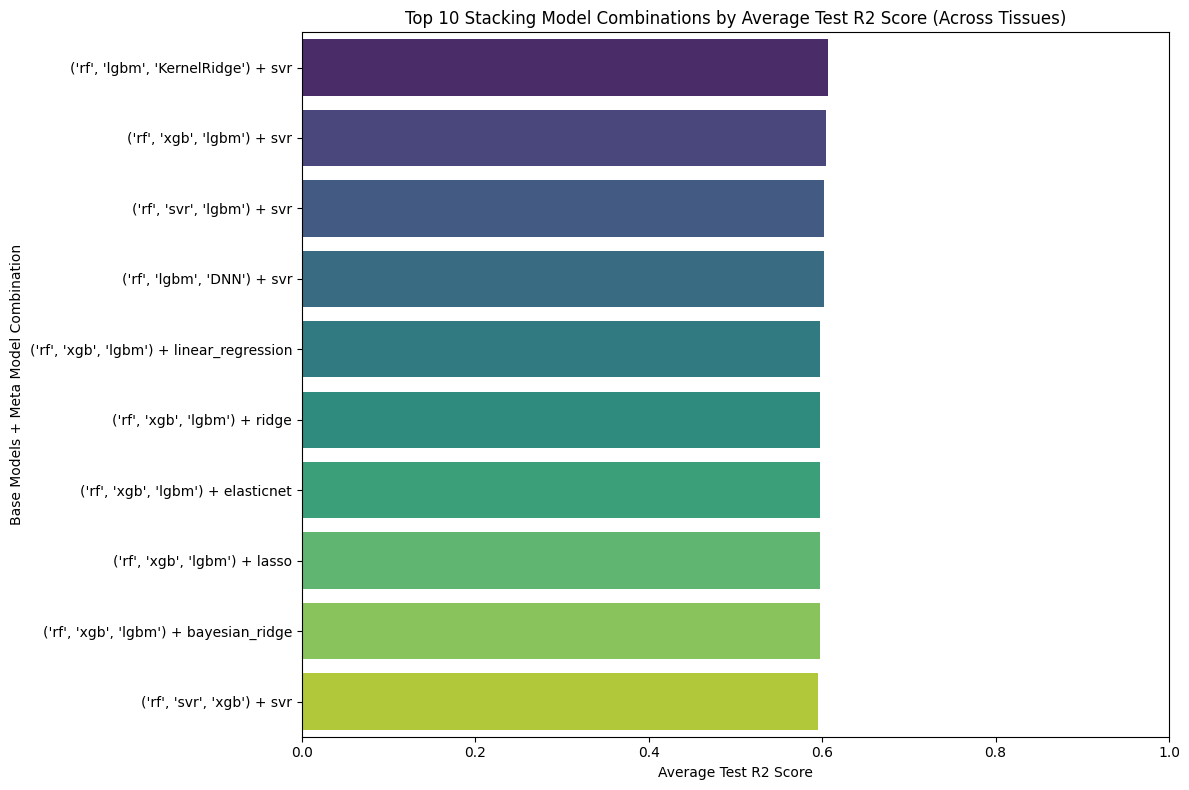

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Calculate the average test_R2 for each combination of base_models and meta_model
avg_r2_results = final_combined_results_df.groupby(['base_models', 'meta_model'])['test_R2'].mean().reset_index()

# Create a combined label for plotting
avg_r2_results['combination'] = avg_r2_results['base_models'] + ' + ' + avg_r2_results['meta_model']

# Sort the results by test_R2 in descending order to highlight best performers
avg_r2_results = avg_r2_results.sort_values(by='test_R2', ascending=False)

# Select the top N combinations to display for clarity
top_n = 10
plot_data = avg_r2_results.head(top_n)

plt.figure(figsize=(12, 8))
sns.barplot(x='test_R2', y='combination', data=plot_data, palette='viridis')
plt.xlabel('Average Test R2 Score')
plt.ylabel('Base Models + Meta Model Combination')
plt.title(f'Top {top_n} Stacking Model Combinations by Average Test R2 Score (Across Tissues)')
plt.xlim(0, 1) # R2 scores are typically between 0 and 1
plt.tight_layout()
plt.show()

In [ ]:
final_combined_results_df[
    (final_combined_results_df['meta_model'] == 'svr')
]

,base_models,meta_model,tissue,cv_RMSE_mean,cv_RMSE_sd,cv_R2_mean,cv_R2_sd,cv_RMSE(mean±sd),cv_R2(mean±sd),test_RMSE,test_R2
30,"('rf', 'svr', 'xgb')",svr,Heart,1.071975,0.102641,0.610041,0.099249,1.072 ± 0.103,0.610 ± 0.099,0.925127,0.640277
31,"('rf', 'svr', 'xgb')",svr,Kidney,1.019428,0.168721,0.583674,0.086153,1.019 ± 0.169,0.584 ± 0.086,1.028094,0.669574
32,"('rf', 'svr', 'xgb')",svr,Liver,0.967656,0.097873,0.581561,0.049127,0.968 ± 0.098,0.582 ± 0.049,1.021265,0.581669
33,"('rf', 'svr', 'xgb')",svr,Lung,0.980138,0.054378,0.672012,0.034140,0.980 ± 0.054,0.672 ± 0.034,0.739969,0.675493
34,"('rf', 'svr', 'xgb')",svr,Spleen,1.244385,0.180743,0.543163,0.086824,1.244 ± 0.181,0.543 ± 0.087,1.027277,0.648700
...,...,...,...,...,...,...,...,...,...,...,...
715,"('lgbm', 'KernelRidge', 'DNN')",svr,Kidney,0.978252,0.152887,0.613424,0.094249,0.978 ± 0.153,0.613 ± 0.094,1.005473,0.683954
716,"('lgbm', 'KernelRidge', 'DNN')",svr,Liver,0.999541,0.111263,0.553320,0.062084,1.000 ± 0.111,0.553 ± 0.062,1.029687,0.574741
717,"('lgbm', 'KernelRidge', 'DNN')",svr,Lung,1.022394,0.069230,0.640537,0.061409,1.022 ± 0.069,0.641 ± 0.061,0.744877,0.671173
718,"('lgbm', 'KernelRidge', 'DNN')",svr,Spleen,1.248160,0.176236,0.538219,0.097750,1.248 ± 0.176,0.538 ± 0.098,0.998308,0.668233


In [ ]:
#Save to csv
final_combined_results_df.to_csv(
    "/content/drive/MyDrive/Colab Notebooks/MTL/Instance_based/stacking_results_20260609.csv",
    index=False,
    encoding="utf-8-sig"
)

## Plot

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

selected_base_models = ('KernelRidge', 'lgbm', 'rf')
selected_meta_model_name = 'svr'

# Filter train_meta_X and test_meta_X for the selected base models
train_meta_X_combo_specific = pd.DataFrame(index=X_train_df.index)
test_meta_X_combo_specific = pd.DataFrame(index=X_test_df.index)

for model_name in selected_base_models:
    train_meta_X_combo_specific[model_name] = train_meta_X[model_name]
    test_meta_X_combo_specific[model_name] = test_meta_X[model_name]

# Build and train the specific meta-model
meta_model_specific = build_meta_model(selected_meta_model_name)
meta_model_specific.fit(train_meta_X_combo_specific, y_train)

# Make predictions on the test set
test_pred_specific = meta_model_specific.predict(test_meta_X_combo_specific)

# Calculate predictions on the full training set for the selected meta-model (for tissue plots)
y_pred_train_specific = meta_model_specific.predict(train_meta_X_combo_specific)


Saving individual tissue plots to: /content/drive/MyDrive/Colab Notebooks/MTL/Instance_based/stacking_multi_meta_colab/individual_tissue_plots
Generating plot for tissue: Heart


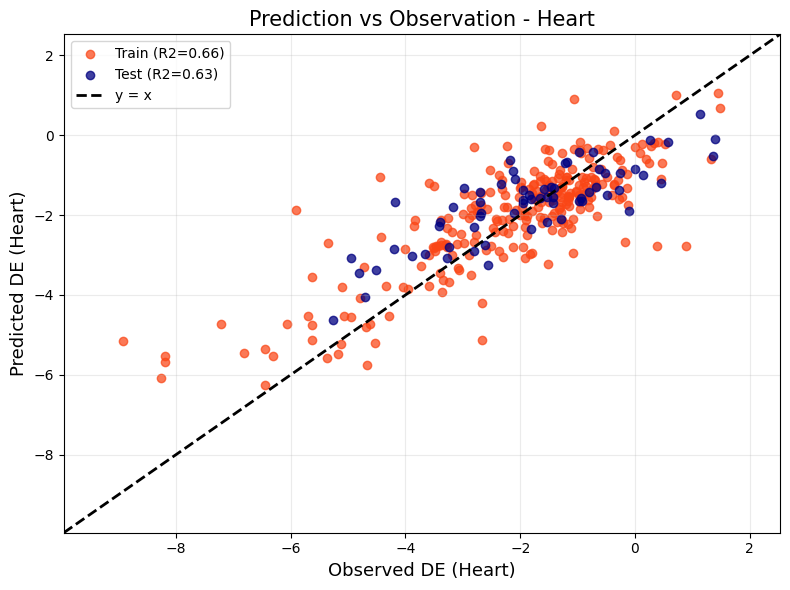

Generating plot for tissue: Kidney


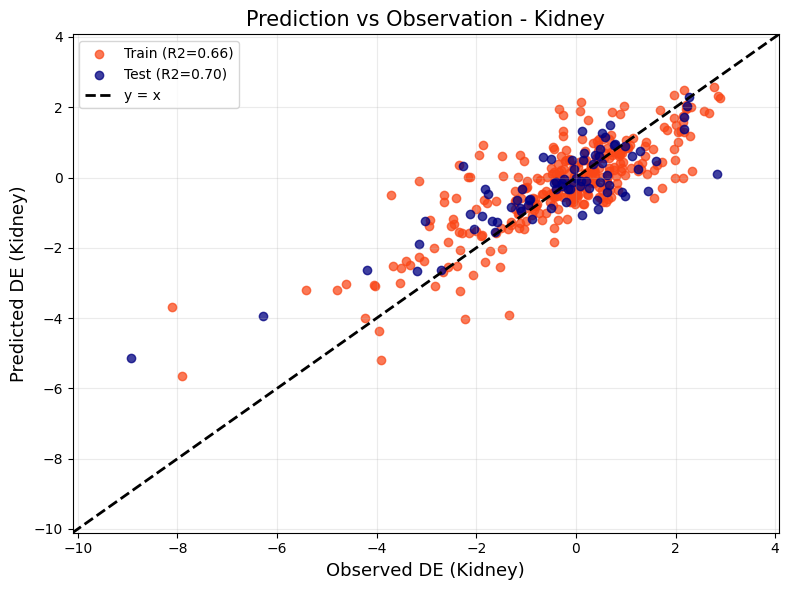

Generating plot for tissue: Liver


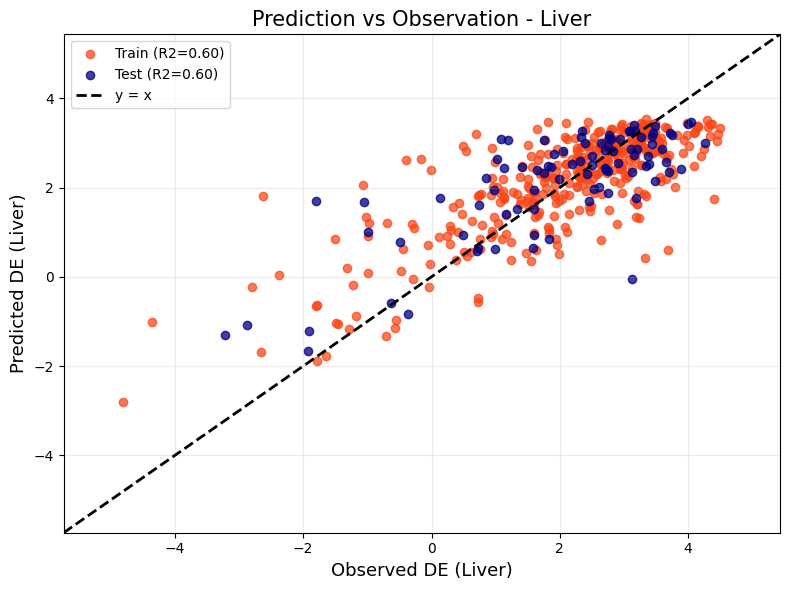

Generating plot for tissue: Lung


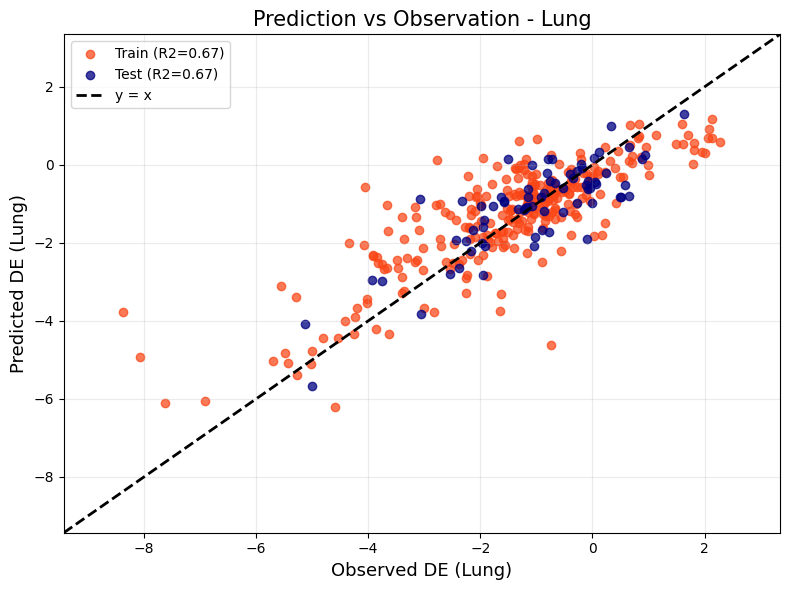

Generating plot for tissue: Spleen


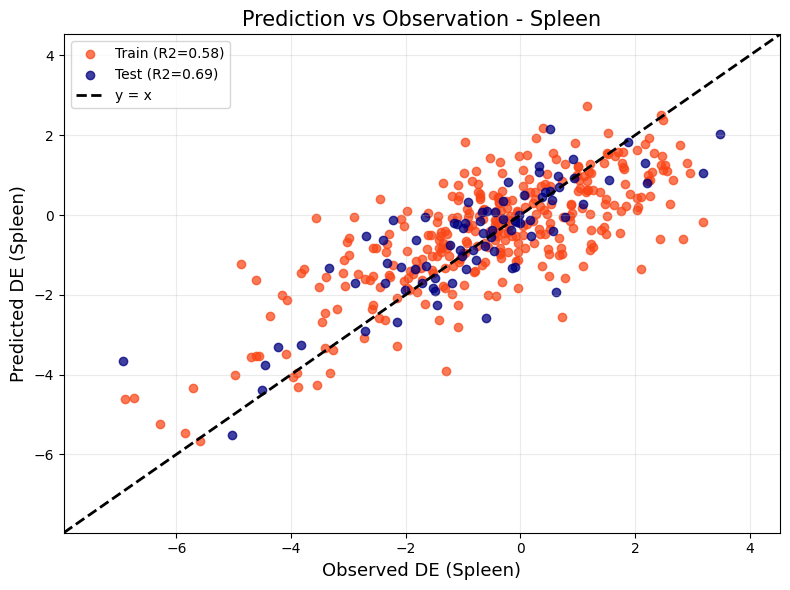

Generating plot for tissue: Tumor


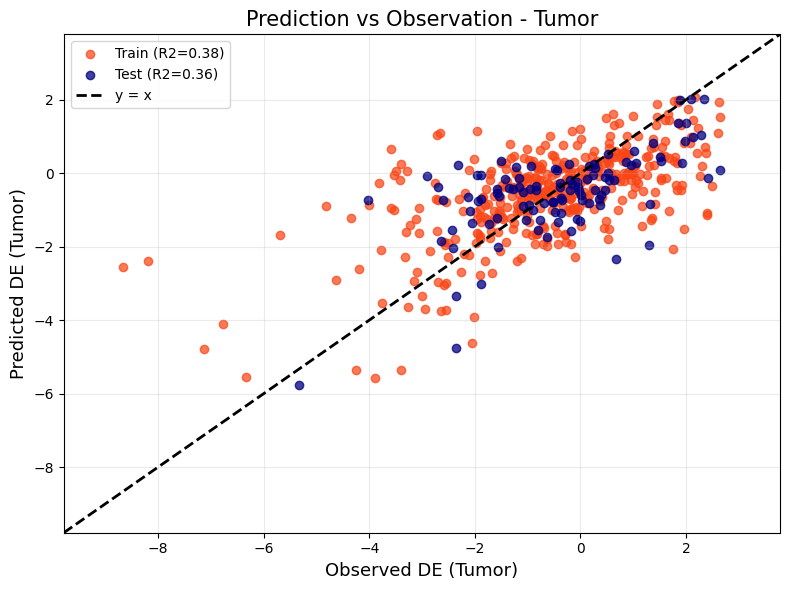

All individual tissue plots generated and saved.


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import r2_score

# Define output directory for plots
plot_output_dir = OUTPUT_DIR / 'individual_tissue_plots'
plot_output_dir.mkdir(parents=True, exist_ok=True)
print(f'Saving individual tissue plots to: {plot_output_dir}')

# Get unique tissues
tissues = sorted(np.unique(np.concatenate([tissue_train, tissue_test])))

# Iterate through each tissue and create plots
for t in tissues:
    print(f'Generating plot for tissue: {t}')
    tr_mask = tissue_train == t
    te_mask = tissue_test == t

    y_tr = y_train[tr_mask]
    p_tr = y_pred_train_specific[tr_mask]
    y_te = y_test[te_mask]
    p_te = test_pred_specific[te_mask]

    r2_tr = r2_score(y_tr, p_tr)
    r2_te = r2_score(y_te, p_te)

    all_vals = np.concatenate([y_tr, p_tr, y_te, p_te])
    mn, mx = float(all_vals.min()), float(all_vals.max())
    pad = 0.1 * (mx - mn) if mx > mn else 0.5

    plt.figure(figsize=(8, 6))
    plt.scatter(y_tr, p_tr, c="#FA4616", alpha=0.72, label=f"Train (R2={r2_tr:.2f})")
    plt.scatter(y_te, p_te, c="#000080", alpha=0.75, label=f"Test (R2={r2_te:.2f})")

    plt.plot([mn - pad, mx + pad], [mn - pad, mx + pad], "--", color="black", linewidth=2, label="y = x")
    plt.xlim(mn - pad, mx + pad)
    plt.ylim(mn - pad, mx + pad)
    plt.xlabel(f"Observed DE ({t})", fontsize=13)
    plt.ylabel(f"Predicted DE ({t})", fontsize=13)
    plt.title(f"Prediction vs Observation - {t}", fontsize=15)
    plt.grid(True, alpha=0.25)
    plt.legend(loc="upper left", fontsize=10)
    plt.tight_layout()

    out_png = plot_output_dir / f"stacking_regression_svr_{t}.png"
    plt.savefig(out_png, dpi=300, bbox_inches="tight")
    plt.show()
    plt.close()

print("All individual tissue plots generated and saved.")

In [ ]:
# Compile all observed and predicted values for all tissues and datasets
plot_data_rows = []
tissues = sorted(np.unique(np.concatenate([tissue_train, tissue_test])))

for t in tissues:
    for dataset, tissue_arr, y_true, y_pred in [
        ("train", tissue_train, y_train, y_pred_train_specific),
        ("test", tissue_test, y_test, test_pred_specific),
    ]:
        mask = tissue_arr == t
        for obs, pred in zip(y_true[mask], y_pred[mask]):
            plot_data_rows.append({
                "tissue": t,
                "dataset": dataset,
                "observed": float(obs),
                "predicted": float(pred)
            })

plotting_data_df = pd.DataFrame(plot_data_rows)

plotting_data_output_path = OUTPUT_DIR / "individual_tissue_predictions.csv"
plotting_data_df.to_csv(plotting_data_output_path, index=False, encoding="utf-8-sig")

print(f"Plotting data grouped by tissue saved to: {plotting_data_output_path}")

Plotting data grouped by tissue saved to: /content/drive/MyDrive/Colab Notebooks/MTL/Instance_based/stacking_multi_meta_colab/individual_tissue_predictions.csv


## Save the model

In [ ]:
import json
import shutil
from pathlib import Path
import joblib
import pandas as pd


class FinalStackingModel:
    def __init__(self, base_models, meta_model, feature_columns, base_model_names):
        self.base_models = base_models
        self.meta_model = meta_model
        self.feature_columns = list(feature_columns)
        self.base_model_names = list(base_model_names)

    def _prepare_X(self, X):
        X = X.copy()
        missing_cols = [c for c in self.feature_columns if c not in X.columns]
        if missing_cols:
            raise ValueError(f"Missing required feature columns: {missing_cols}")
        return X.loc[:, self.feature_columns]

    def build_meta_features(self, X):
        X = self._prepare_X(X)
        meta_X = pd.DataFrame(index=X.index)
        for name in self.base_model_names:
            meta_X[name] = self.base_models[name].predict(X)
        return meta_X

    def predict(self, X):
        meta_X = self.build_meta_features(X)
        return self.meta_model.predict(meta_X)

    def save(self, save_dir):
        save_dir = Path(save_dir)
        if save_dir.exists():
            shutil.rmtree(save_dir)
        save_dir.mkdir(parents=True, exist_ok=True)

        models_dir = save_dir / "models"
        models_dir.mkdir(parents=True, exist_ok=True)

        for name in self.base_model_names:
            joblib.dump(self.base_models[name], models_dir / f"{name}.joblib")

        joblib.dump(self.meta_model, models_dir / "meta_model.joblib")

        config = {
            "feature_columns": self.feature_columns,
            "base_model_names": self.base_model_names,
        }
        with open(save_dir / "config.json", "w", encoding="utf-8") as f:
            json.dump(config, f, indent=2, ensure_ascii=False)

        print(f"Saved to: {save_dir}")

    @classmethod
    def load(cls, save_dir):
        save_dir = Path(save_dir)
        models_dir = save_dir / "models"

        with open(save_dir / "config.json", "r", encoding="utf-8") as f:
            config = json.load(f)

        base_models = {
            name: joblib.load(models_dir / f"{name}.joblib")
            for name in config["base_model_names"]
        }
        meta_model = joblib.load(models_dir / "meta_model.joblib")

        return cls(
            base_models=base_models,
            meta_model=meta_model,
            feature_columns=config["feature_columns"],
            base_model_names=config["base_model_names"],
        )


In [ ]:
final_base_models = ("svr", "xgb", "rf")
final_meta_model_name = "svr"

train_meta_X_final = train_meta_X.loc[:, list(final_base_models)].copy()
final_meta_model = build_meta_model(final_meta_model_name)
final_meta_model.fit(train_meta_X_final, y_train)

final_stacking_model = FinalStackingModel(
    base_models={name: fitted_base_models[name] for name in final_base_models},
    meta_model=final_meta_model,
    feature_columns=X_train_df.columns.tolist(),
    base_model_names=final_base_models,
)

final_stacking_model.save(
    '/content/drive/MyDrive/Colab Notebooks/MTL/Instance_based/final_stacking_model_package'
)


Saved to: /content/drive/MyDrive/Colab Notebooks/MTL/Instance_based/final_stacking_model_package


In [ ]:
######Test ssave model
from sklearn.metrics import mean_squared_error, r2_score
import numpy as np
import pandas as pd

# predict
loaded_model = FinalStackingModel.load('/content/drive/MyDrive/Colab Notebooks/MTL/Instance_based/final_stacking_model_package')
y_pred = loaded_model.predict(X_test_df)

# detailed comparison table
comparison_df = pd.DataFrame({
    "Tissue": tissue_test,
    "Observed": y_test,
    "Predicted": y_pred
})

comparison_df["Residual"] = comparison_df["Observed"] - comparison_df["Predicted"]
comparison_df["Absolute_Error"] = np.abs(comparison_df["Residual"])

# per-tissue metrics
tissue_results = []
for tissue_name, group in comparison_df.groupby("Tissue", sort=True):
    y_true_t = group["Observed"].to_numpy()
    y_pred_t = group["Predicted"].to_numpy()

    tissue_results.append({
        "Tissue": tissue_name,
        "N": len(group),
        "RMSE": np.sqrt(mean_squared_error(y_true_t, y_pred_t)),
        "R2": np.nan if len(group) < 2 else r2_score(y_true_t, y_pred_t),
        "Mean_Observed": np.mean(y_true_t),
        "Mean_Predicted": np.mean(y_pred_t),
        "Mean_Absolute_Error": np.mean(np.abs(y_true_t - y_pred_t)),
    })

tissue_metrics_df = pd.DataFrame(tissue_results).sort_values("Tissue").reset_index(drop=True)

print("Per-tissue performance:")
display(tissue_metrics_df)


Per-tissue performance:


,Tissue,N,RMSE,R2,Mean_Observed,Mean_Predicted,Mean_Absolute_Error
0,Heart,66,0.906739,0.654435,-1.850274,-1.727636,0.727282
1,Kidney,78,1.024749,0.671721,-0.396502,-0.252314,0.715702
2,Liver,90,1.036900,0.568762,2.010253,2.099625,0.746095
3,Lung,72,0.761782,0.656079,-1.048110,-1.061137,0.604536
4,Spleen,82,0.992377,0.672164,-0.803950,-0.691477,0.744755
5,Tumor,105,1.155216,0.373168,-0.410573,-0.524301,0.885981


## AD

Applicable domain feature space: PCA95 (20 components)
Global AD threshold, q=0.95: 1.3962
Saved AD outputs to: /content/drive/MyDrive/Colab Notebooks/MTL/Instance_based/stacking_multi_meta_colab/applicable_domain_analysis

Per-tissue AD coverage on test set:


,Tissue,N_test,N_inside_AD,Mean_AD_Distance,Distance_threshold,AD_Reference,N_outside_AD,Inside_AD_percent
0,Heart,66,61,0.608969,1.461086,tissue-specific,5,92.424242
1,Kidney,78,69,0.592307,1.402927,tissue-specific,9,88.461538
2,Liver,90,83,0.666186,1.380934,tissue-specific,7,92.222222
3,Lung,72,64,0.623987,1.396361,tissue-specific,8,88.888889
4,Spleen,82,77,0.582696,1.439156,tissue-specific,5,93.902439
5,Tumor,105,103,0.514921,1.374967,tissue-specific,2,98.095238



Per-tissue test performance inside vs outside AD:


,Tissue,AD_Group,N,Percent_of_test_tissue,RMSE,R2,MAE,Mean_AD_Distance,Distance_threshold,AD_Reference
0,Heart,Inside AD,61,92.424242,0.935157,0.635683,0.754042,0.515501,1.461086,tissue-specific
1,Heart,Outside AD,5,7.575758,0.428475,0.894398,0.400819,1.749278,1.461086,tissue-specific
2,Kidney,Inside AD,69,88.461538,1.023778,0.679003,0.692074,0.460881,1.402927,tissue-specific
3,Kidney,Outside AD,9,11.538462,1.032163,0.434477,0.896856,1.599906,1.402927,tissue-specific
4,Liver,Inside AD,83,92.222222,1.055897,0.548757,0.754799,0.589888,1.380934,tissue-specific
5,Liver,Outside AD,7,7.777778,0.777013,0.716341,0.642895,1.570873,1.380934,tissue-specific
6,Lung,Inside AD,64,88.888889,0.780022,0.596987,0.615257,0.505130,1.396361,tissue-specific
7,Lung,Outside AD,8,11.111111,0.596099,0.856016,0.518767,1.574848,1.396361,tissue-specific
8,Spleen,Inside AD,77,93.902439,0.990750,0.681333,0.742050,0.517052,1.439156,tissue-specific
9,Spleen,Outside AD,5,6.097561,1.017096,0.368985,0.786427,1.593609,1.439156,tissue-specific


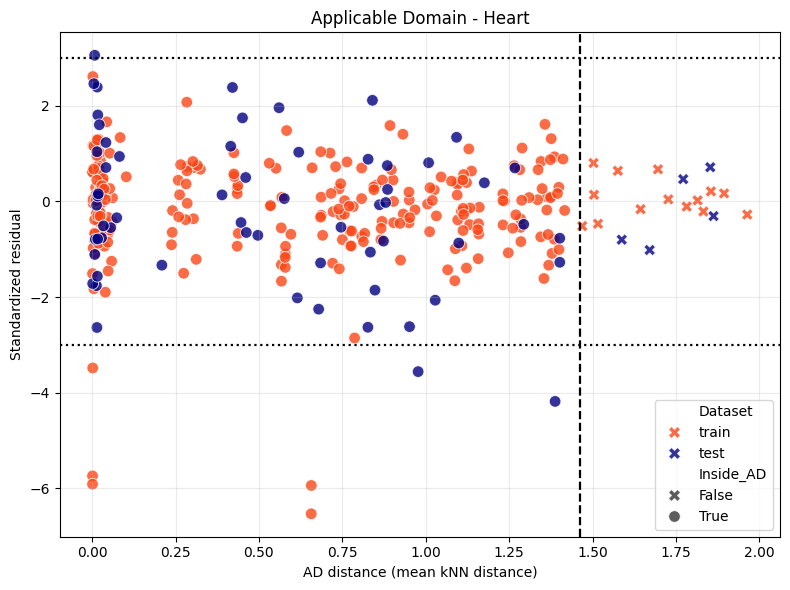

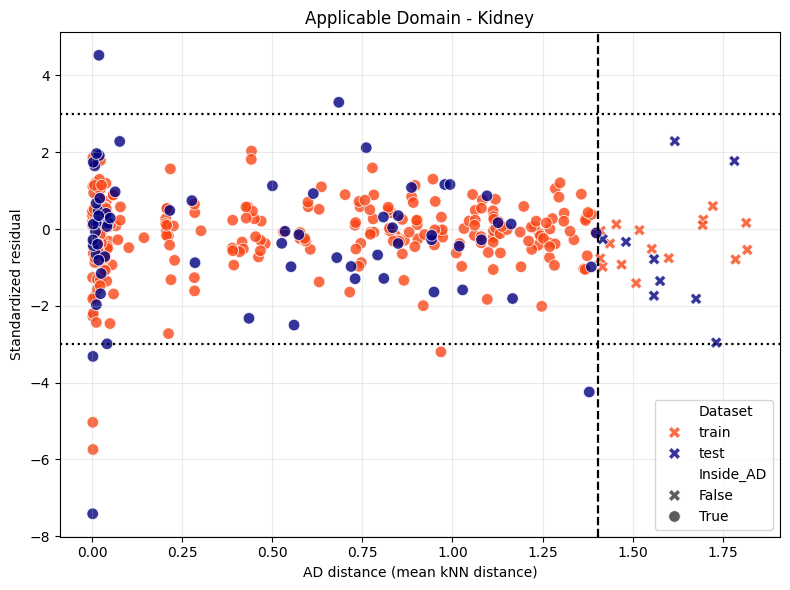

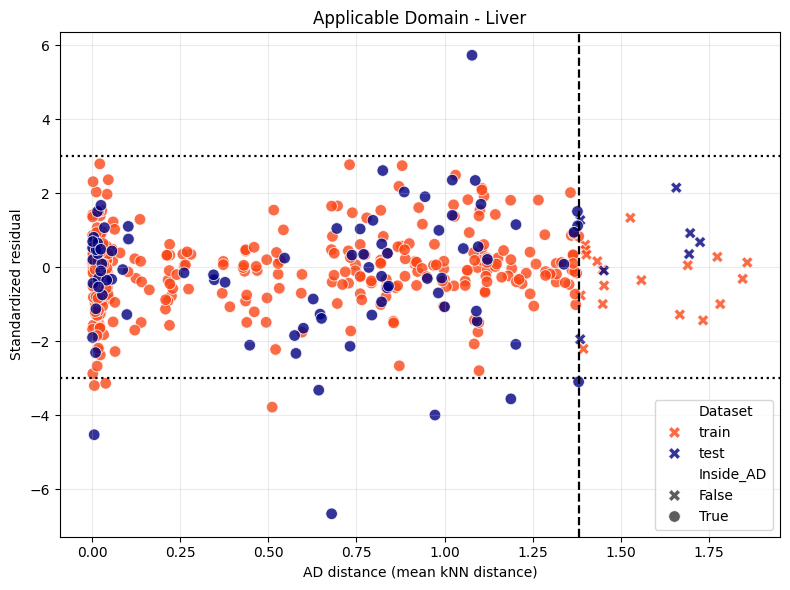

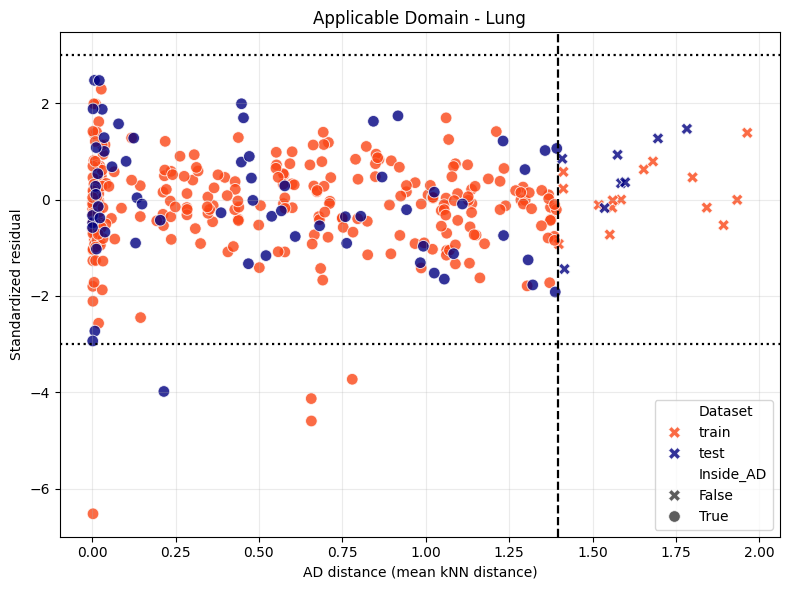

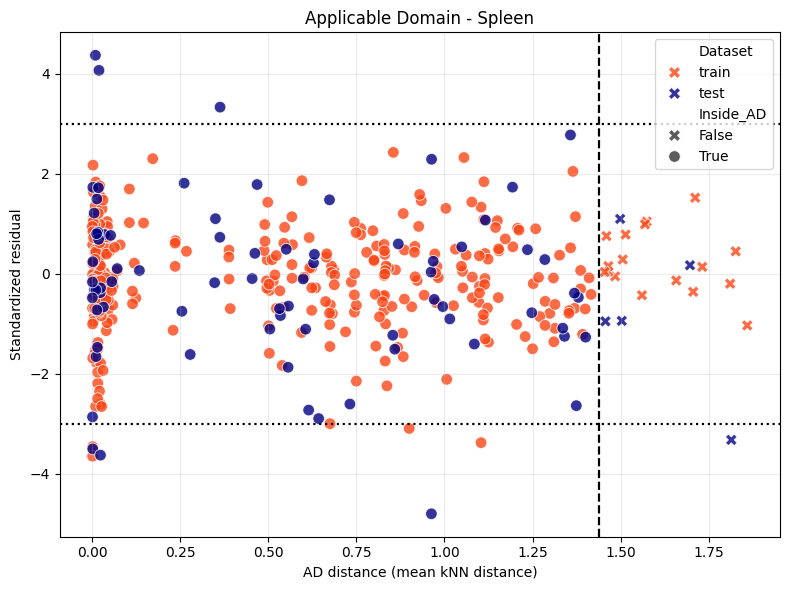

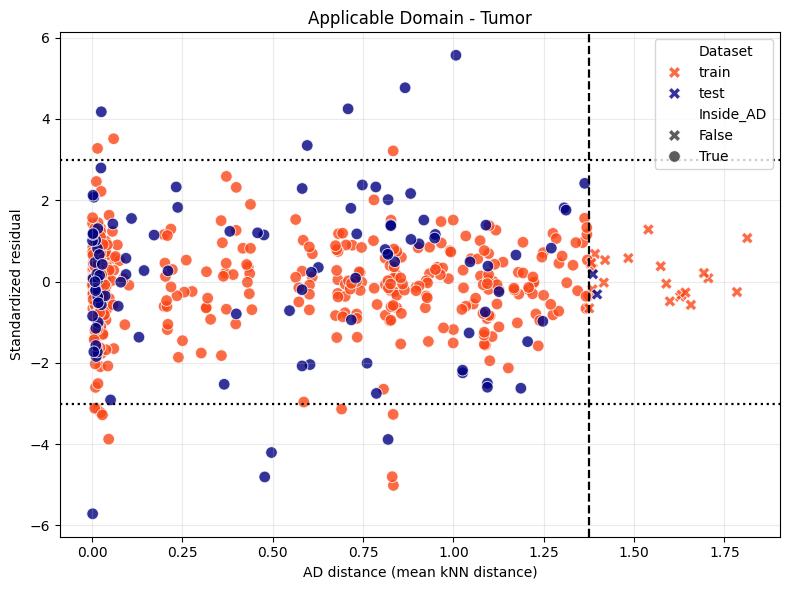

Individual tissue AD plots saved to: /content/drive/MyDrive/Colab Notebooks/MTL/Instance_based/stacking_multi_meta_colab/applicable_domain_analysis/individual_tissue_AD_plots


In [ ]:
# Applicable Domain (AD) analysis for the final stacking model by tissue
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.decomposition import PCA
from sklearn.metrics import r2_score
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import StandardScaler

# Use the final stacking model loaded/trained in the previous cells.

ad_output_dir = OUTPUT_DIR / "applicable_domain_analysis"
ad_plot_dir = ad_output_dir / "individual_tissue_AD_plots"
ad_output_dir.mkdir(parents=True, exist_ok=True)
ad_plot_dir.mkdir(parents=True, exist_ok=True)

ad_feature_columns = list(getattr(loaded_model, "feature_columns", X_train_df.columns.tolist()))
X_train_ad_df = X_train_df.loc[:, ad_feature_columns].copy()
X_test_ad_df = X_test_df.loc[:, ad_feature_columns].copy()


max_pca_components = min(X_train_ad_df.shape[0] - 1, X_train_ad_df.shape[1])
if max_pca_components >= 2:
    pca_ad = PCA(n_components=0.95, svd_solver="full", random_state=SPLIT_SEED)
    X_train_space = pca_ad.fit_transform(X_train_ad_df)
    X_test_space = pca_ad.transform(X_test_ad_df)
    ad_space_name = f"PCA95 ({X_train_space.shape[1]} components)"
else:
    pca_ad = None
    X_train_space = X_train_ad_df
    X_test_space = X_test_ad_df
    ad_space_name = "Descriptor space"

# Final stacking model predictions.
y_train_ad_pred = loaded_model.predict(X_train_ad_df)
y_test_ad_pred = loaded_model.predict(X_test_ad_df)
train_residual = y_train - y_train_ad_pred
test_residual = y_test - y_test_ad_pred
train_resid_sd = float(np.std(train_residual, ddof=1)) if len(train_residual) > 1 else np.nan

if np.isfinite(train_resid_sd) and train_resid_sd > 0:
    train_std_residual = train_residual / train_resid_sd
    test_std_residual = test_residual / train_resid_sd
else:
    train_std_residual = np.full_like(train_residual, np.nan, dtype=float)
    test_std_residual = np.full_like(test_residual, np.nan, dtype=float)


def self_knn_scores(X_ref, k):
    """Mean distance to k nearest neighbors in the training reference set."""
    if len(X_ref) <= 1:
        return np.zeros(len(X_ref), dtype=float)
    k_self = min(k + 1, len(X_ref))
    nn = NearestNeighbors(n_neighbors=k_self, metric="euclidean")
    nn.fit(X_ref)
    distances, _ = nn.kneighbors(X_ref)
    return distances[:, 1:].mean(axis=1)


def query_knn_scores(X_ref, X_query, k):
    """Mean distance from query samples to k nearest training neighbors."""
    if len(X_query) == 0:
        return np.array([], dtype=float)
    k_query = max(1, min(k, len(X_ref)))
    nn = NearestNeighbors(n_neighbors=k_query, metric="euclidean")
    nn.fit(X_ref)
    distances, _ = nn.kneighbors(X_query)
    return distances.mean(axis=1)


AD_K = 5
AD_QUANTILE = 0.95
MIN_TISSUE_REF_N = max(AD_K + 1, 6)

global_train_scores = self_knn_scores(X_train_space, AD_K)
global_threshold = float(np.quantile(global_train_scores, AD_QUANTILE))
global_test_scores = query_knn_scores(X_train_space, X_test_space, AD_K)

train_ad_rows = []
test_ad_rows = []
ad_reference_rows = []

for tissue_name in sorted(np.unique(np.concatenate([tissue_train, tissue_test]))):
    tr_mask = tissue_train == tissue_name
    te_mask = tissue_test == tissue_name

    X_ref = X_train_space[tr_mask]
    X_query = X_test_space[te_mask]

    use_tissue_specific_ref = len(X_ref) >= MIN_TISSUE_REF_N
    if use_tissue_specific_ref:
        ref_scores = self_knn_scores(X_ref, AD_K)
        threshold = float(np.quantile(ref_scores, AD_QUANTILE))
        query_scores = query_knn_scores(X_ref, X_query, AD_K)
        ref_label = "tissue-specific"
    else:
        ref_scores = global_train_scores[tr_mask]
        threshold = global_threshold
        query_scores = global_test_scores[te_mask]
        ref_label = "global fallback"

    ad_reference_rows.append({
        "Tissue": tissue_name,
        "Reference": ref_label,
        "N_train_reference": int(len(X_ref)),
        "AD_k": int(min(AD_K, max(1, len(X_ref)))),
        "AD_quantile": AD_QUANTILE,
        "Distance_threshold": threshold,
        "AD_space": ad_space_name,
    })

    tr_indices = np.where(tr_mask)[0]
    tr_scores = ref_scores if use_tissue_specific_ref else global_train_scores[tr_mask]
    for local_i, row_i in enumerate(tr_indices):
        train_ad_rows.append({
            "Dataset": "train",
            "Tissue": tissue_name,
            "Observed": float(y_train[row_i]),
            "Predicted": float(y_train_ad_pred[row_i]),
            "Residual": float(train_residual[row_i]),
            "Abs_Error": float(abs(train_residual[row_i])),
            "Std_Residual": float(train_std_residual[row_i]),
            "AD_Distance": float(tr_scores[local_i]),
            "AD_Threshold": threshold,
            "Inside_AD": bool(tr_scores[local_i] <= threshold),
            "AD_Reference": ref_label,
        })

    te_indices = np.where(te_mask)[0]
    for local_i, row_i in enumerate(te_indices):
        test_ad_rows.append({
            "Dataset": "test",
            "Tissue": tissue_name,
            "Observed": float(y_test[row_i]),
            "Predicted": float(y_test_ad_pred[row_i]),
            "Residual": float(test_residual[row_i]),
            "Abs_Error": float(abs(test_residual[row_i])),
            "Std_Residual": float(test_std_residual[row_i]),
            "AD_Distance": float(query_scores[local_i]),
            "AD_Threshold": threshold,
            "Inside_AD": bool(query_scores[local_i] <= threshold),
            "AD_Reference": ref_label,
        })

ad_sample_df = pd.DataFrame(train_ad_rows + test_ad_rows)
ad_reference_df = pd.DataFrame(ad_reference_rows)

summary_rows = []
for tissue_name, group in ad_sample_df[ad_sample_df["Dataset"] == "test"].groupby("Tissue", sort=True):
    for inside_value, label in [(True, "Inside AD"), (False, "Outside AD")]:
        subset = group[group["Inside_AD"] == inside_value]
        if len(subset) == 0:
            summary_rows.append({
                "Tissue": tissue_name,
                "AD_Group": label,
                "N": 0,
                "Percent_of_test_tissue": 0.0,
                "RMSE": np.nan,
                "R2": np.nan,
                "MAE": np.nan,
                "Mean_AD_Distance": np.nan,
                "Distance_threshold": float(group["AD_Threshold"].iloc[0]),
                "AD_Reference": group["AD_Reference"].iloc[0],
            })
            continue

        y_true = subset["Observed"].to_numpy()
        y_pred = subset["Predicted"].to_numpy()
        residual = subset["Residual"].to_numpy()
        summary_rows.append({
            "Tissue": tissue_name,
            "AD_Group": label,
            "N": int(len(subset)),
            "Percent_of_test_tissue": 100.0 * len(subset) / len(group),
            "RMSE": float(np.sqrt(np.mean(residual ** 2))),
            "R2": np.nan if len(subset) < 2 else float(r2_score(y_true, y_pred)),
            "MAE": float(subset["Abs_Error"].mean()),
            "Mean_AD_Distance": float(subset["AD_Distance"].mean()),
            "Distance_threshold": float(subset["AD_Threshold"].iloc[0]),
            "AD_Reference": subset["AD_Reference"].iloc[0],
        })

ad_summary_by_tissue_df = pd.DataFrame(summary_rows)
coverage_by_tissue_df = (
    ad_sample_df[ad_sample_df["Dataset"] == "test"]
    .groupby("Tissue", sort=True)
    .agg(
        N_test=("Inside_AD", "size"),
        N_inside_AD=("Inside_AD", "sum"),
        Mean_AD_Distance=("AD_Distance", "mean"),
        Distance_threshold=("AD_Threshold", "first"),
        AD_Reference=("AD_Reference", "first"),
    )
    .reset_index()
)
coverage_by_tissue_df["N_outside_AD"] = coverage_by_tissue_df["N_test"] - coverage_by_tissue_df["N_inside_AD"]
coverage_by_tissue_df["Inside_AD_percent"] = 100.0 * coverage_by_tissue_df["N_inside_AD"] / coverage_by_tissue_df["N_test"]

ad_sample_path = ad_output_dir / "applicable_domain_sample_level.csv"
ad_summary_path = ad_output_dir / "applicable_domain_per_tissue_metrics.csv"
ad_reference_path = ad_output_dir / "applicable_domain_reference_thresholds.csv"
ad_coverage_path = ad_output_dir / "applicable_domain_per_tissue_coverage.csv"

ad_sample_df.to_csv(ad_sample_path, index=False, encoding="utf-8-sig")
ad_summary_by_tissue_df.to_csv(ad_summary_path, index=False, encoding="utf-8-sig")
ad_reference_df.to_csv(ad_reference_path, index=False, encoding="utf-8-sig")
coverage_by_tissue_df.to_csv(ad_coverage_path, index=False, encoding="utf-8-sig")

print("Applicable domain feature space:", ad_space_name)
print(f"Global AD threshold, q={AD_QUANTILE}: {global_threshold:.4f}")
print("Saved AD outputs to:", ad_output_dir)
print("\nPer-tissue AD coverage on test set:")
display(coverage_by_tissue_df)
print("\nPer-tissue test performance inside vs outside AD:")
display(ad_summary_by_tissue_df)

# Individual tissue plots: AD distance vs Residual.
for tissue_name in sorted(ad_sample_df["Tissue"].unique()):
    tissue_plot_df = ad_sample_df[ad_sample_df["Tissue"] == tissue_name].copy()
    threshold = float(tissue_plot_df["AD_Threshold"].iloc[0])

    plt.figure(figsize=(8, 6))
    sns.scatterplot(
        data=tissue_plot_df,
        x="AD_Distance",
        y="Std_Residual",
        hue="Dataset",
        style="Inside_AD",
        markers={True: "o", False: "X"},
        palette={"train": "#FA4616", "test": "#000080"},
        s=70,
        alpha=0.8,
    )
    plt.axvline(threshold, color="black", linestyle="--", linewidth=1.6, label="AD threshold")
    plt.axhline(3, color="black", linestyle=":", linewidth=1.6)
    plt.axhline(-3, color="black", linestyle=":", linewidth=1.6)
    plt.xlabel("AD distance (mean kNN distance)")
    plt.ylabel("Standardized residual")
    plt.title(f"Applicable Domain - {tissue_name}")
    plt.grid(True, alpha=0.25)
    plt.tight_layout()

    safe_tissue_name = str(tissue_name).replace("/", "_").replace("\\", "_").replace(" ", "_")
    out_png = ad_plot_dir / f"applicable_domain_{safe_tissue_name}.png"
    plt.savefig(out_png, dpi=300, bbox_inches="tight")
    plt.show()
    plt.close()

print("Individual tissue AD plots saved to:", ad_plot_dir)
